#Main Figures

###Figure 1

NUMERICAL CHECKS
-------------------------------------------
c = 0.25:
  b_a,- = 0.325350678
  b_a,+ = 0.924649322

c = 0:
  b_a,- = 0.087349035
  b_a,+ = 0.912650965

Cusp:
  c*   = 0.984000000
  b_a* = 0.992000000

fold sum at c=0.25 = 1.25
expected             = 1.25


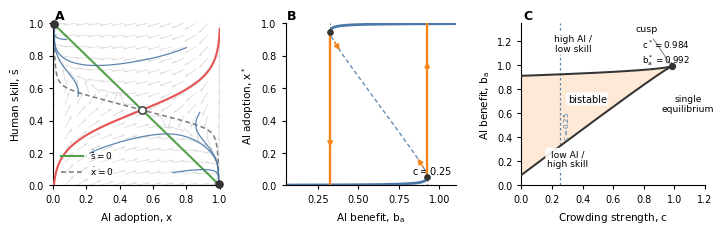


Saved:
figures-PNAS/fig_meanfield.pdf
figures-PNAS/fig_meanfield_values.txt


In [ ]:
# ============================================================
# FIGURE 1 — REDUCED MEAN-FIELD MODEL
# Three panels:
# A) phase portrait
# B) S-shaped equilibrium curve + hysteresis at c = 0.25
# C) phase diagram in (c, b_a)
#
# ============================================================

import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from scipy.integrate import solve_ivp


# ============================================================
# PARAMETERS
# ============================================================

b_h = 1.0
eta = 0.0
eps = 0.05
m = 0.002

# Reference crowding used in panels A and B
c_ref = 0.25

# Panel A
b_a_phase = 0.60


# ============================================================
# OUTPUT
# ============================================================

outdir = "figures-PNAS"
os.makedirs(outdir, exist_ok=True)

pdf_path = os.path.join(outdir, "fig_meanfield.pdf")
txt_path = os.path.join(outdir, "fig_meanfield_values.txt")


# ============================================================
# STYLE
# ============================================================

cm = 1 / 2.54

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Liberation Sans"],

    "font.size": 7.5,
    "axes.labelsize": 7.5,
    "xtick.labelsize": 7.0,
    "ytick.labelsize": 7.0,
    "legend.fontsize": 6.5,

    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "mathtext.default": "regular",
})

BLUE   = "#4C78A8"
ORANGE = "#F58518"
GREEN  = "#54A24B"
RED    = "#E45756"
GRAY   = "#7F7F7F"
LIGHT  = "#D9D9D9"
DARK   = "#333333"


# ============================================================
# MODEL
# ============================================================

def Gamma(c):
    return b_h * (1 - eta) - c


def rhs(t, y, b_a, c):

    x, s = y

    dx = (
        x * (1 - x) *
        (b_a - c*x - b_h*s)
        + m*(1 - 2*x)
    )

    ds = eps * (
        1 - (1 - eta)*x - s
    )

    return [dx, ds]


def jacobian(x, s, b_a, c):

    g = b_a - c*x - b_h*s

    J11 = (
        (1 - 2*x)*g
        - c*x*(1 - x)
        - 2*m
    )

    J12 = -b_h*x*(1 - x)
    J21 = -eps*(1 - eta)
    J22 = -eps

    return np.array([
        [J11, J12],
        [J21, J22]
    ])


# ============================================================
# NULLCLINES
# ============================================================

def s_nullcline(x):
    return 1 - (1 - eta)*x


def x_nullcline(x, b_a, c):

    return (
        b_a
        - c*x
        + m*(1 - 2*x)/(x*(1 - x))
    ) / b_h


# ============================================================
# EQUILIBRIUM CURVE
# ============================================================

def b_a_of_x(x, c):

    return (
        b_h
        - Gamma(c)*x
        + m*(2*x - 1)/(x*(1 - x))
    )


# ============================================================
# FOLD POINTS
# ============================================================

def fold_xs(c):

    G = Gamma(c)

    # No folds when Gamma <= 8m
    if G <= 8*m:
        return None

    f = lambda x: (
        m*(1/x**2 + 1/(1-x)**2)
        - G
    )

    x_small = brentq(
        f,
        1e-9,
        0.5 - 1e-9
    )

    x_large = brentq(
        f,
        0.5 + 1e-9,
        1 - 1e-9
    )

    return x_small, x_large


def fold_values(c):

    roots = fold_xs(c)

    if roots is None:
        return None

    x_small, x_large = roots

    # small-x root = upper fold
    b_plus = b_a_of_x(x_small, c)

    # large-x root = lower fold
    b_minus = b_a_of_x(x_large, c)

    return x_small, x_large, b_minus, b_plus


# ============================================================
# EQUILIBRIA FOR FIXED b_a
# ============================================================

def equilibria(b_a, c):

    f = lambda x: (
        b_a_of_x(x, c) - b_a
    )

    xx = np.linspace(
        1e-6,
        1 - 1e-6,
        8000
    )

    yy = f(xx)

    roots = []

    for i in range(len(xx)-1):

        if yy[i]*yy[i+1] < 0:

            r = brentq(
                f,
                xx[i],
                xx[i+1]
            )

            if not any(
                abs(r-r0) < 1e-7
                for r0 in roots
            ):
                roots.append(r)

    output = []

    for x in roots:

        s = s_nullcline(x)

        eig = np.linalg.eigvals(
            jacobian(x, s, b_a, c)
        )

        stable = np.all(
            np.real(eig) < 0
        )

        output.append(
            (x, s, stable)
        )

    return output


# ============================================================
# OTHER STABLE ROOT AT SAME b_a
# Used to draw vertical hysteresis jumps
# ============================================================

def other_stable_root(b_a, c, branch):

    x_small, x_large = fold_xs(c)

    f = lambda x: (
        b_a_of_x(x, c) - b_a
    )

    if branch == "high":

        a = x_large + 1e-6
        b = 1 - 1e-6

    else:

        a = 1e-6
        b = x_small - 1e-6

    xx = np.linspace(a, b, 4000)
    yy = f(xx)

    for i in range(len(xx)-1):

        if yy[i]*yy[i+1] < 0:

            return brentq(
                f,
                xx[i],
                xx[i+1]
            )

    return xx[np.argmin(np.abs(yy))]


# ============================================================
# IMPORTANT NUMERICAL VALUES
# ============================================================

xsmall_ref, xlarge_ref, ba_minus_ref, ba_plus_ref = fold_values(c_ref)

c_star = b_h*(1 - eta) - 8*m

ba_star = (
    b_h*(1 + eta) + c_star
) / 2


# Fold values at c = 0
_, _, ba_minus_c0, ba_plus_c0 = fold_values(0.0)


print("NUMERICAL CHECKS")
print("-------------------------------------------")
print(f"c = 0.25:")
print(f"  b_a,- = {ba_minus_ref:.9f}")
print(f"  b_a,+ = {ba_plus_ref:.9f}")
print()
print(f"c = 0:")
print(f"  b_a,- = {ba_minus_c0:.9f}")
print(f"  b_a,+ = {ba_plus_c0:.9f}")
print()
print(f"Cusp:")
print(f"  c*   = {c_star:.9f}")
print(f"  b_a* = {ba_star:.9f}")
print()
print(
    "fold sum at c=0.25 =",
    ba_minus_ref + ba_plus_ref
)
print(
    "expected             =",
    b_h*(1 + eta) + c_ref
)


# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17.8*cm, 5.8*cm),
    gridspec_kw={
        "width_ratios": [1.0, 1.02, 1.10]
    }
)

axA, axB, axC = axes


# ============================================================
# PANEL A — PHASE PORTRAIT
# ============================================================

xx = np.linspace(0, 1, 15)
ss = np.linspace(0, 1, 15)

X, S = np.meshgrid(xx, ss)

DX = (
    X*(1-X) *
    (b_a_phase - c_ref*X - b_h*S)
    + m*(1 - 2*X)
)

DS = eps * (
    1 - (1-eta)*X - S
)

speed = np.sqrt(
    DX**2 + DS**2
)

DXn = DX/(speed + 1e-12)
DSn = DS/(speed + 1e-12)


# flow field
axA.quiver(
    X, S,
    DXn, DSn,
    angles="xy",
    scale_units="xy",
    scale=12,
    width=0.005,
    color=LIGHT,
    alpha=0.9,
    zorder=0
)


# nullclines
x_plot = np.linspace(
    0.002,
    0.998,
    4000
)

s_nc = s_nullcline(
    x_plot
)

x_nc = x_nullcline(
    x_plot,
    b_a_phase,
    c_ref
)

mask = (
    (x_nc >= 0)
    & (x_nc <= 1)
)


axA.plot(
    x_plot,
    s_nc,
    color=GREEN,
    lw=1.5,
    label=r"$\dot{\bar{s}}=0$"
)

axA.plot(
    x_plot[mask],
    x_nc[mask],
    color=GRAY,
    lw=1.15,
    ls=(0,(3,2)),
    label=r"$\dot{x}=0$"
)


# equilibria
eqs = equilibria(
    b_a_phase,
    c_ref
)

for xeq, seq, stable in eqs:

    if stable:

        axA.plot(
            xeq,
            seq,
            "o",
            ms=5.2,
            color=DARK,
            zorder=8,
            clip_on=False
        )

    else:

        x_sad = xeq
        s_sad = seq

        axA.plot(
            xeq,
            seq,
            "o",
            ms=5.3,
            mfc="white",
            mec=DARK,
            mew=1.0,
            zorder=9,
            clip_on=False
        )


# ============================================================
# STABLE MANIFOLD OF SADDLE
# ============================================================

J = jacobian(
    x_sad,
    s_sad,
    b_a_phase,
    c_ref
)

eigval, eigvec = np.linalg.eig(J)

stable_index = np.argmin(
    np.real(eigval)
)

v = np.real(
    eigvec[:, stable_index]
)

v /= np.linalg.norm(v)


for sign in (-1, 1):

    y0 = (
        np.array([x_sad, s_sad])
        + sign*1e-6*v
    )

    sol = solve_ivp(
        lambda t, y:
            -np.asarray(
                rhs(
                    t,
                    y,
                    b_a_phase,
                    c_ref
                )
            ),
        [0, 250],
        y0,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.25
    )

    xb = sol.y[0]
    sb = sol.y[1]

    keep = (
        (xb >= 0)
        & (xb <= 1)
        & (sb >= 0)
        & (sb <= 1)
    )

    axA.plot(
        xb[keep],
        sb[keep],
        color=RED,
        lw=1.55,
        zorder=5
    )


# ============================================================
# REPRESENTATIVE TRAJECTORIES
# ============================================================

starts = [
    (0.08, 0.90),
    (0.15, 0.55),
    (0.22, 0.20),
    (0.80, 0.85),
    (0.88, 0.45),
    (0.72, 0.08),
]


for y0 in starts:

    sol = solve_ivp(
        lambda t, y:
            rhs(
                t,
                y,
                b_a_phase,
                c_ref
            ),
        [0, 250],
        y0,
        max_step=0.5,
        rtol=1e-7,
        atol=1e-9
    )

    axA.plot(
        sol.y[0],
        sol.y[1],
        color=BLUE,
        lw=0.9,
        alpha=0.90,
        zorder=2
    )


axA.set_xlim(0, 1)
axA.set_ylim(0, 1)

axA.set_xlabel(
    r"AI adoption, $x$"
)

axA.set_ylabel(
    r"Human skill, $\bar{s}$"
)

axA.legend(
    frameon=False,
    loc="lower left",
    handlelength=2.4
)

axA.text(
    0.01,
    1.025,
    "A",
    transform=axA.transAxes,
    fontsize=9,
    fontweight="bold"
)


# ============================================================
# PANEL B — S-CURVE + HYSTERESIS
# c = 0.25 ONLY
# ============================================================

x_small, x_large, b_minus, b_plus = fold_values(
    c_ref
)


# three parts of equilibrium curve
x_low = np.linspace(
    0.002,
    x_small,
    700
)

x_mid = np.linspace(
    x_small,
    x_large,
    1200
)

x_high = np.linspace(
    x_large,
    0.998,
    700
)


# stable branches
axB.plot(
    b_a_of_x(x_low, c_ref),
    x_low,
    color=BLUE,
    lw=2.0
)

axB.plot(
    b_a_of_x(x_high, c_ref),
    x_high,
    color=BLUE,
    lw=2.0
)


# saddle branch
axB.plot(
    b_a_of_x(x_mid, c_ref),
    x_mid,
    color=BLUE,
    lw=1.0,
    ls=(0,(3,2)),
    alpha=0.85
)


# fold vertical guides
axB.axvline(
    b_minus,
    color=GRAY,
    lw=0.75,
    ls=(0,(1.5,2.0)),
    zorder=0
)

axB.axvline(
    b_plus,
    color=GRAY,
    lw=0.75,
    ls=(0,(1.5,2.0)),
    zorder=0
)


# exact endpoints of hysteresis jumps
x_top = other_stable_root(
    b_plus,
    c_ref,
    "high"
)

x_bottom = other_stable_root(
    b_minus,
    c_ref,
    "low"
)


# jumps
axB.plot(
    [b_plus, b_plus],
    [x_small, x_top],
    color=ORANGE,
    lw=1.7,
    zorder=5
)

axB.plot(
    [b_minus, b_minus],
    [x_large, x_bottom],
    color=ORANGE,
    lw=1.7,
    zorder=5
)


# ============================================================
# ARROWS — ONLY ON SWEEP PATH
# ============================================================

# increasing b_a: lower branch
axB.annotate(
    "",
    xy=(
        b_a_of_x(0.18, c_ref),
        0.18
    ),
    xytext=(
        b_a_of_x(0.10, c_ref),
        0.10
    ),
    arrowprops=dict(
        arrowstyle="-|>",
        color=ORANGE,
        lw=1.05,
        mutation_scale=8
    )
)


# jump upward
axB.annotate(
    "",
    xy=(
        b_plus,
        0.78
    ),
    xytext=(
        b_plus,
        0.56
    ),
    arrowprops=dict(
        arrowstyle="-|>",
        color=ORANGE,
        lw=1.05,
        mutation_scale=8
    )
)


# decreasing b_a: upper branch
axB.annotate(
    "",
    xy=(
        b_a_of_x(0.82, c_ref),
        0.82
    ),
    xytext=(
        b_a_of_x(0.90, c_ref),
        0.90
    ),
    arrowprops=dict(
        arrowstyle="-|>",
        color=ORANGE,
        lw=1.05,
        mutation_scale=8
    )
)


# jump downward
axB.annotate(
    "",
    xy=(
        b_minus,
        0.22
    ),
    xytext=(
        b_minus,
        0.44
    ),
    arrowprops=dict(
        arrowstyle="-|>",
        color=ORANGE,
        lw=1.05,
        mutation_scale=8
    )
)


# fold points
axB.plot(
    b_minus,
    x_large,
    "o",
    ms=3.8,
    color=DARK,
    zorder=6
)

axB.plot(
    b_plus,
    x_small,
    "o",
    ms=3.8,
    color=DARK,
    zorder=6
)


axB.set_xlim(
    0.05,
    1.10
)

axB.set_ylim(
    0,
    1
)

axB.set_xlabel(
    r"AI benefit, $b_a$"
)

axB.set_ylabel(
    r"AI adoption, $x^*$"
)


# Small direct annotation rather than a legend
axB.text(
    0.98,
    0.055,
    r"$c=0.25$",
    transform=axB.transAxes,
    ha="right",
    va="bottom",
    fontsize=7
)


axB.text(
    0.01,
    1.025,
    "B",
    transform=axB.transAxes,
    fontsize=9,
    fontweight="bold"
)


# ============================================================
# PANEL C — PHASE DIAGRAM IN (c, b_a)
# ============================================================

c_grid = np.linspace(
    0,
    1.2,
    800
)

ba_minus = np.full_like(
    c_grid,
    np.nan
)

ba_plus = np.full_like(
    c_grid,
    np.nan
)


for i, c in enumerate(c_grid):

    values = fold_values(c)

    if values is not None:

        _, _, bm, bp = values

        ba_minus[i] = bm
        ba_plus[i] = bp


mask = (
    np.isfinite(ba_minus)
    & np.isfinite(ba_plus)
)


# bistability shading
axC.fill_between(
    c_grid[mask],
    ba_minus[mask],
    ba_plus[mask],
    color=ORANGE,
    alpha=0.18,
    lw=0,
    zorder=0
)


# fold boundaries
axC.plot(
    c_grid[mask],
    ba_minus[mask],
    color=DARK,
    lw=1.45,
    zorder=3
)

axC.plot(
    c_grid[mask],
    ba_plus[mask],
    color=DARK,
    lw=1.45,
    zorder=3
)


# ============================================================
# CUSP
# ============================================================

axC.plot(
    c_star,
    ba_star,
    "o",
    color=DARK,
    ms=4.2,
    zorder=7
)

axC.annotate(
    r"cusp",
    xy=(
        c_star,
        ba_star
    ),
    xytext=(
        0.82,
        1.28
    ),
    fontsize=6.8,
    ha="center",
    arrowprops=dict(
        arrowstyle="-",
        color=GRAY,
        lw=0.7
    )
)

axC.text(
    0.79,
    1.105,
    rf"$c^*={c_star:.3f}$" + "\n" +
    rf"$b_a^*={ba_star:.3f}$",
    fontsize=6.3,
    ha="left",
    va="center"
)


# ============================================================
# REFERENCE c = 0.25
# ============================================================

axC.axvline(
    c_ref,
    color=BLUE,
    lw=0.9,
    ls=(0,(2,2)),
    alpha=0.9,
    zorder=2
)

axC.text(
    c_ref + 0.018,
    0.38,
    r"$c=0.25$",
    color=BLUE,
    fontsize=5,
    rotation=90,
    va="bottom",
    ha="left"
)


# ============================================================
# REGION LABELS
# ============================================================

box = dict(
    boxstyle="round,pad=0.16",
    facecolor="white",
    edgecolor="none",
    alpha=0.90
)


# Below lower fold
axC.text(
    0.30,
    0.22,
    "low AI /\nhigh skill",
    fontsize=6.6,
    ha="center",
    va="center",
    bbox=box,
    zorder=10
)


# Inside bistable wedge
axC.text(
    0.43,
    0.72,
    "bistable",
    fontsize=7.0,
    ha="center",
    va="center",
    bbox=box,
    zorder=10
)


# Above upper fold
axC.text(
    0.34,
    1.18,
    "high AI /\nlow skill",
    fontsize=6.6,
    ha="center",
    va="center",
    bbox=box,
    zorder=10
)


# Right of cusp
axC.text(
    1.09,
    0.68,
    "single\nequilibrium",
    fontsize=6.6,
    ha="center",
    va="center",
    bbox=box,
    zorder=10
)


axC.set_xlim(
    0,
    1.2
)

axC.set_ylim(
    0,
    1.35
)

axC.set_xlabel(
    r"Crowding strength, $c$"
)

axC.set_ylabel(
    r"AI benefit, $b_a$"
)

axC.text(
    0.01,
    1.025,
    "C",
    transform=axC.transAxes,
    fontsize=9,
    fontweight="bold"
)


# ============================================================
# COMMON STYLE
# ============================================================

for ax in axes:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        direction="out"
    )


plt.subplots_adjust(
    left=0.065,
    right=0.995,
    bottom=0.22,
    top=0.93,
    wspace=0.38
)


# ============================================================
# SAVE
# ============================================================

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE NUMERICAL VALUES
# ============================================================

with open(
    txt_path,
    "w"
) as f:

    f.write(
        "Mean-field Figure 1 values\n"
    )

    f.write(
        "==========================\n\n"
    )

    f.write(
        f"b_h = {b_h}\n"
    )

    f.write(
        f"eta = {eta}\n"
    )

    f.write(
        f"epsilon = {eps}\n"
    )

    f.write(
        f"m = {m}\n\n"
    )

    f.write(
        "Reference case c = 0.25\n"
    )

    f.write(
        f"b_a,- = {ba_minus_ref:.9f}\n"
    )

    f.write(
        f"b_a,+ = {ba_plus_ref:.9f}\n"
    )

    f.write(
        f"sum = {ba_minus_ref + ba_plus_ref:.9f}\n\n"
    )

    f.write(
        "At c = 0\n"
    )

    f.write(
        f"b_a,- = {ba_minus_c0:.9f}\n"
    )

    f.write(
        f"b_a,+ = {ba_plus_c0:.9f}\n\n"
    )

    f.write(
        "Cusp\n"
    )

    f.write(
        f"c* = {c_star:.9f}\n"
    )

    f.write(
        f"b_a* = {ba_star:.9f}\n"
    )


print("\nSaved:")
print(pdf_path)
print(txt_path)

###Figure 2

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
beta = 0.5, w = 0.25, mu = 0.00049975, time factor = 0.24987506
m recovered = 0.00200000 (target 0.002)
Gamma_eff: eps_c = 5.5299  (rho_c ~ 2.759)
shared-skill folds: [0.32535068 0.92464932]
  eps= 0.05: b_a- = 0.3482, b_a+ = 0.9259, width = 0.5777
  eps= 0.50: b_a- = 0.5129, b_a+ = 0.9357, width = 0.4228
  eps= 1.00: b_a- = 0.6373, b_a+ = 0.9443, width = 0.3070
  eps= 2.00: b_a- = 0.7911, b_a+ = 0.9573, width = 0.1662
  eps= 3.00: b_a- = 0.8813, b_a+ = 0.9675, width = 0.0862
  eps= 4.00: b_a- = 0.9394, b_a+ = 0.9764, width = 0.0370
  eps= 6.00: no bistability
Saved results: eps=2: 3 reps, eps=0.05: 3 reps, eps=0.5: 3 reps, eps=1: 3 reps, eps=3: 3 reps, eps=4: 3 reps, eps=6: 3 reps

Running ABM: N = 4000, 61 values of b_a, reps = 3
Simulation time this session: 0.0 min

 eps    theory   ABM   (reps)
 0.05   0.5777   0.5801 +/- 0.0090  (3)
 0.50   0.4228   0.4

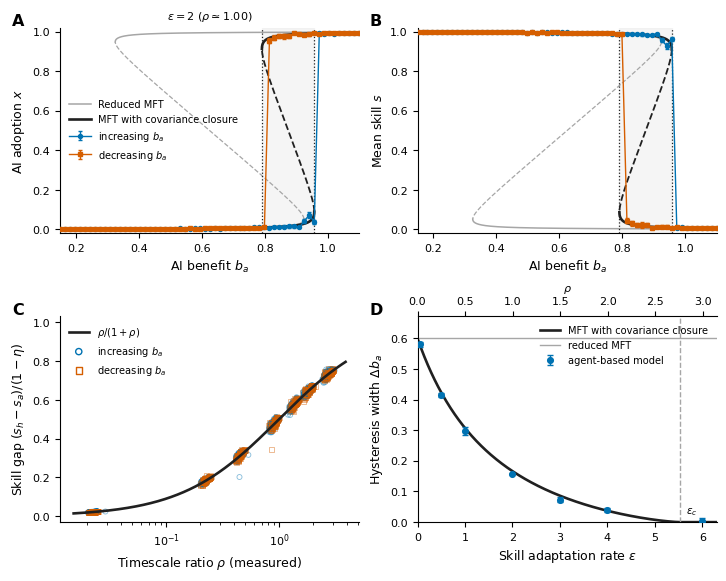


Finished. Files in /content/drive/MyDrive/PNAS_private_skill_hysteresis
Caption data: N=4000, k=50, beta=0.5, mu=4.998e-04 (m=0.002), 61 values of b_a in [0.15, 1.1], relaxation 1200 sweeps, measurement 300 sweeps every 5, 3 repetitions; width = difference between the b_a at which the two branches cross x = 1/2.


In [ ]:
# ================================================================
# PNAS FIGURE 2 — PRIVATE SKILLS, HYSTERESIS, AND Gamma_eff
#
#   (A) AI reliance x vs b_a: agent-based hysteresis, shared-skill
#       theory and Gamma_eff theory (at EPS_PANEL)
#   (B) mean skill vs b_a
#   (C) measured skill gap (s_h - s_a)/(1-eta) vs rho/(1+rho)
#   (D) hysteresis width vs epsilon (top axis: rho)
#
# The run is resumable: results are saved (to Google Drive when
# available) after every repetition, and rerunning the cell resumes
# from the last saved repetition. Set PLOT_ONLY = True to redraw the
# figure from saved results without simulating.
#
# Units: epsilon and m are in the rescaled time of the mean-field
# equations; one sweep = one revision per agent on average;
# conversion factor (1 - mu) * beta / 2.
# ================================================================

import sys, subprocess, time, csv, pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar

try:
    from numba import njit
except ImportError:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numba"])
        from numba import njit
    except Exception:
        print("numba unavailable: running in pure Python (slow; use SMOKE_TEST).")
        def njit(f=None, **kw):
            return f if f is not None else (lambda g: g)


# ================================================================
# 1. PARAMETERS
# ================================================================

SMOKE_TEST = False          # True: tiny run to check the code end to end
PLOT_ONLY = False           # True: plot from saved results, no simulation

B = 1.0                     # b_h
C = 0.25                    # c
ETA = 0.0                   # eta
M = 0.002                   # m (rescaled units)
BETA_SEL = 0.5              # selection intensity beta

N = 4000                    # population size
K_SAMPLE = 50               # agents sampled to estimate crowding

A_MIN, A_MAX, N_A = 0.15, 1.10, 61
EPS_VALUES = np.array([0.05, 0.50, 1.00, 2.00, 3.00, 4.00, 6.00])
EPS_PANEL = 2.00            # epsilon shown in panels A-B (must be in EPS_VALUES)

EQUIL_SWEEPS = 1200.0       # relaxation at each b_a
SAMPLE_SWEEPS = 300.0       # measurement window
SAMPLE_EVERY = 5.0          # sweeps between snapshots
N_REPS = 3                  # independent repetitions
SEED = 12345
MIN_GROUP_AGENTS = 10       # min agents per strategy to estimate s_h, s_a

if SMOKE_TEST:
    N, N_A, N_REPS = 60, 9, 1
    EPS_VALUES = np.array([0.05, 2.0, 6.0]); EPS_PANEL = 2.0
    EQUIL_SWEEPS, SAMPLE_SWEEPS, SAMPLE_EVERY = 15.0, 10.0, 5.0

assert float(EPS_PANEL) in [float(e) for e in EPS_VALUES], "EPS_PANEL must be in EPS_VALUES"

A_UP = np.linspace(A_MIN, A_MAX, N_A)
A_DOWN = A_UP[::-1].copy()

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/PNAS_private_skill_hysteresis")
except ImportError:
    OUTPUT_DIR = Path("PNAS_private_skill_hysteresis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT = OUTPUT_DIR / f"runs_N{N}_beta{BETA_SEL}_c{C}.pkl"


# ================================================================
# 2. TIME CONVENTIONS
# ================================================================

w = BETA_SEL / 2.0
MU = M * w / (1.0 + M * w)          # inverts m = mu / [(1 - mu) w]
TIME_FACTOR = (1.0 - MU) * w        # tau = TIME_FACTOR * t_sweep
DELTA = 1.0 - ETA

print("=" * 72)
print(f"beta = {BETA_SEL}, w = {w}, mu = {MU:.8f}, time factor = {TIME_FACTOR:.8f}")
print(f"m recovered = {MU / TIME_FACTOR:.8f} (target {M})")
print("=" * 72)


# ================================================================
# 3. THEORY
# ================================================================

def lambda_pred_sweep(x):
    """Total per-capita switching rate per sweep at weak selection."""
    x = np.asarray(x, dtype=float)
    return (1.0 - MU) / 2.0 + 2.0 * MU + MU * (1.0 - 2.0 * x) ** 2 / (2.0 * x * (1.0 - x))

def rho_pred(x, epsilon):
    return epsilon * TIME_FACTOR / lambda_pred_sweep(x)

def gamma_eff(x, epsilon):
    return B * DELTA / (1.0 + rho_pred(x, epsilon)) - C

def a_effective(x, epsilon):
    """Equilibrium curve b_a(x) with Gamma_eff."""
    x = np.asarray(x, dtype=float)
    return B - gamma_eff(x, epsilon) * x + M * (2.0 * x - 1.0) / (x * (1.0 - x))

def a_shared(x):
    """Equilibrium curve of the shared-skill (rho -> 0) theory."""
    x = np.asarray(x, dtype=float)
    return B - (B * DELTA - C) * x + M * (2.0 * x - 1.0) / (x * (1.0 - x))

XGRID = np.linspace(0.0025, 0.9975, 7000)

def folds_of(curve):
    """Folds of a sampled equilibrium curve: local max (upper fold) and
    local min (lower fold), refined by bounded minimization."""
    aa = curve(XGRID)
    da = np.diff(aa)
    idx = np.where(np.sign(da[:-1]) != np.sign(da[1:]))[0] + 1
    if len(idx) < 2:
        return None
    ext = []
    for i in (idx[0], idx[-1]):
        lo = XGRID[max(i - 3, 0)]
        hi = XGRID[min(i + 3, len(XGRID) - 1)]
        sign = -1.0 if aa[i] > aa[i - 1] else 1.0
        r = minimize_scalar(lambda xx, s=sign: s * float(curve(xx)),
                            bounds=(lo, hi), method="bounded",
                            options={"xatol": 1e-10})
        ext.append((r.x, float(curve(r.x))))
    xs = np.array([e[0] for e in ext]); as_ = np.array([e[1] for e in ext])
    o = np.argsort(as_)
    return {"x": xs[o], "a": as_[o], "width": float(as_[o][1] - as_[o][0])}

def theory_folds(epsilon):
    return folds_of(lambda x: a_effective(x, epsilon))

SHARED_FOLDS = folds_of(a_shared)

def min_slope(epsilon):
    return float(np.min(np.gradient(a_effective(XGRID, epsilon), XGRID)))

eps_hi = 0.5
while min_slope(eps_hi) < 0.0 and eps_hi < 200:
    eps_hi *= 2.0
EPS_CRIT = brentq(min_slope, 0.0, eps_hi)
RHO_CRIT = float(rho_pred(0.5, EPS_CRIT))

print(f"Gamma_eff: eps_c = {EPS_CRIT:.4f}  (rho_c ~ {RHO_CRIT:.3f})")
print(f"shared-skill folds: {SHARED_FOLDS['a'] if SHARED_FOLDS else None}")
for ee in EPS_VALUES:
    ff = theory_folds(float(ee))
    print(f"  eps={ee:5.2f}: " + ("no bistability" if ff is None else
          f"b_a- = {ff['a'][0]:.4f}, b_a+ = {ff['a'][1]:.4f}, width = {ff['width']:.4f}"))


# ================================================================
# 4. AGENT-BASED MODEL (event driven, exact skill relaxation)
# ================================================================

@njit
def initialise_population(n, x0, s_A_init, seed):
    np.random.seed(seed)
    z = np.zeros(n, dtype=np.int8)
    n_A = int(round(n * x0))
    z[:n_A] = 1
    np.random.shuffle(z)
    s = np.ones(n, dtype=np.float64)
    for i in range(n):
        if z[i] == 1:
            s[i] = s_A_init
    last = np.zeros(n, dtype=np.float64)
    return z, s, last, n_A

@njit
def update_skill(i, z, s, last, t, eta, eps_sweep):
    target = eta if z[i] == 1 else 1.0
    s[i] = target + (s[i] - target) * np.exp(-eps_sweep * (t - last[i]))
    last[i] = t

@njit
def revision_event(z, s, last, n_A, t, a, b, c, eta, beta_sel, mu,
                   eps_sweep, k_sample, count, counts):
    n = z.size
    i = np.random.randint(n)
    old = z[i]
    update_skill(i, z, s, last, t, eta, eps_sweep)
    flip = False
    if np.random.random() < mu:
        flip = True
    else:
        j = np.random.randint(n)
        if z[j] != old:
            update_skill(j, z, s, last, t, eta, eps_sweep)
            x = n_A / n
            crowd = np.random.binomial(k_sample, x) / k_sample   # k sampled agents
            pi_A = a - c * crowd
            if old == 0:
                dpi = pi_A - b * s[i]        # H focal copies A model
            else:
                dpi = b * s[j] - pi_A        # A focal copies H model
            arg = beta_sel * dpi
            if arg > 60.0:
                arg = 60.0
            elif arg < -60.0:
                arg = -60.0
            if np.random.random() < 1.0 / (1.0 + np.exp(-arg)):
                flip = True
    if flip:
        z[i] = 1 - old
        if old == 0:
            n_A += 1
        else:
            n_A -= 1
        if count:
            counts[old] += 1                  # 0: H->A, 1: A->H
    return n_A

@njit
def run_branch(a_values, z, s, last, n_A, t0, b, c, eta, beta_sel, mu,
               eps_sweep, k_sample, equil_sweeps, sample_sweeps,
               sample_every, seed):
    np.random.seed(seed)
    n = z.size
    na = a_values.size
    mean_x = np.empty(na); std_x = np.empty(na)
    mean_s = np.empty(na); std_s = np.empty(na)
    mean_h = np.empty(na); mean_g = np.empty(na)
    rate_HA = np.empty(na); rate_AH = np.empty(na)
    t = t0
    next_event = t + np.random.exponential(1.0 / n)
    dummy = np.zeros(2, dtype=np.int64)

    for ia in range(na):
        a_now = a_values[ia]
        # relaxation
        t_end = t + equil_sweeps
        while next_event <= t_end:
            n_A = revision_event(z, s, last, n_A, next_event, a_now, b, c, eta,
                                 beta_sel, mu, eps_sweep, k_sample, False, dummy)
            next_event += np.random.exponential(1.0 / n)
        t = t_end
        # measurement
        ns = max(1, int(np.floor(sample_sweeps / sample_every)))
        xs = np.empty(ns); ss = np.empty(ns); hs = np.empty(ns); gs = np.empty(ns)
        counts = np.zeros(2, dtype=np.int64)
        exposure = np.zeros(2)
        prev = t
        for q in range(ns):
            ts = t + (q + 1) * sample_every
            while next_event <= ts:
                dt = next_event - prev
                exposure[0] += (n - n_A) * dt
                exposure[1] += n_A * dt
                n_A = revision_event(z, s, last, n_A, next_event, a_now, b, c, eta,
                                     beta_sel, mu, eps_sweep, k_sample, True, counts)
                prev = next_event
                next_event += np.random.exponential(1.0 / n)
            dt = ts - prev
            exposure[0] += (n - n_A) * dt
            exposure[1] += n_A * dt
            prev = ts
            sum_H = 0.0; sum_A = 0.0
            for ii in range(n):
                update_skill(ii, z, s, last, ts, eta, eps_sweep)
                if z[ii] == 1:
                    sum_A += s[ii]
                else:
                    sum_H += s[ii]
            n_H = n - n_A
            xs[q] = n_A / n
            ss[q] = (sum_H + sum_A) / n
            hs[q] = sum_H / n_H if n_H > 0 else np.nan
            gs[q] = sum_A / n_A if n_A > 0 else np.nan
        t = t + ns * sample_every
        mean_x[ia] = np.mean(xs); std_x[ia] = np.std(xs)
        mean_s[ia] = np.mean(ss); std_s[ia] = np.std(ss)
        hsum = 0.0; hc = 0; gsum = 0.0; gc = 0
        for q in range(ns):
            if not np.isnan(hs[q]):
                hsum += hs[q]; hc += 1
            if not np.isnan(gs[q]):
                gsum += gs[q]; gc += 1
        mean_h[ia] = hsum / hc if hc > 0 else np.nan
        mean_g[ia] = gsum / gc if gc > 0 else np.nan
        rate_HA[ia] = counts[0] / exposure[0] if exposure[0] > 0 else np.nan
        rate_AH[ia] = counts[1] / exposure[1] if exposure[1] > 0 else np.nan

    return (mean_x, std_x, mean_s, std_s, mean_h, mean_g, rate_HA, rate_AH,
            z, s, last, n_A, t)


def pack_branch(a_values, out, epsilon):
    mean_x, std_x, mean_s, std_s, mean_h, mean_g, r_HA, r_AH = out[:8]
    return {"a": np.asarray(a_values), "x": mean_x, "x_std": std_x,
            "sbar": mean_s, "s_std": std_s, "h": mean_h, "g": mean_g,
            "gap": mean_h - mean_g, "r_HA": r_HA, "r_AH": r_AH,
            "rho": epsilon * TIME_FACTOR / (r_HA + r_AH)}

def run_sweep(a_values, state, epsilon, seed):
    z, s, last, n_A, t0 = state
    out = run_branch(a_values, z, s, last, n_A, t0, B, C, ETA, BETA_SEL, MU,
                     epsilon * TIME_FACTOR, K_SAMPLE, EQUIL_SWEEPS,
                     SAMPLE_SWEEPS, SAMPLE_EVERY, seed)
    z, s, last, n_A, t = out[-5:]
    return pack_branch(a_values, out, epsilon), (z.copy(), s.copy(), last.copy(), n_A, t)

def simulate_hysteresis(epsilon, rep, n=N):
    base = SEED + 100000 * rep + int(round(1000 * epsilon)) + 7 * n
    z, s, last, n_A = initialise_population(n, 0.02, 1.0, base + 1)
    up, state = run_sweep(A_UP, (z, s, last, n_A, 0.0), epsilon, base + 2)
    down, _ = run_sweep(A_DOWN, state, epsilon, base + 3)
    return up, down


# ================================================================
# 5. FOLD ESTIMATES FROM THE SIMULATIONS
# ================================================================

def crossing(branch, increasing):
    """b_a at which the branch first crosses x = 1/2 (linear interpolation)."""
    a, x = branch["a"], branch["x"]
    hit = np.where(x >= 0.5)[0] if increasing else np.where(x <= 0.5)[0]
    if len(hit) == 0 or hit[0] == 0:
        return np.nan
    k = hit[0]
    return float(a[k - 1] + (0.5 - x[k - 1]) * (a[k] - a[k - 1]) / (x[k] - x[k - 1]))

def observed_window(up, down):
    a_up = crossing(up, True)
    a_down = crossing(down, False)
    width = max(0.0, a_up - a_down) if np.isfinite(a_up) and np.isfinite(a_down) else np.nan
    return {"width": width, "a_up": a_up, "a_down": a_down}


# ================================================================
# 6. MAIN RUN (resumable)
# ================================================================

RUNS = pickle.load(open(CKPT, "rb")) if CKPT.exists() else {}
if RUNS:
    print("Saved results: " + ", ".join(f"eps={e:g}: {len(v)} reps" for e, v in RUNS.items()))

if not PLOT_ONLY:
    eps_order = [float(EPS_PANEL)] + [float(e) for e in EPS_VALUES
                                      if float(e) != float(EPS_PANEL)]
    print(f"\nRunning ABM: N = {N}, {N_A} values of b_a, reps = {N_REPS}")
    t_start = time.perf_counter()
    for epsilon in eps_order:
        RUNS.setdefault(epsilon, [])
        for rep in range(len(RUNS[epsilon]), N_REPS):
            t0 = time.perf_counter()
            up, down = simulate_hysteresis(epsilon, rep)
            win = observed_window(up, down)
            RUNS[epsilon].append({"up": up, "down": down, "window": win})
            with open(CKPT, "wb") as f:
                pickle.dump(RUNS, f)
            print(f"  eps={epsilon:5.2f} rep {rep+1}: width = {win['width']:.4f} "
                  f"(b_a- = {win['a_down']:.3f}, b_a+ = {win['a_up']:.3f})  "
                  f"[{(time.perf_counter()-t0)/60:.1f} min, saved]", flush=True)
    print(f"Simulation time this session: {(time.perf_counter()-t_start)/60:.1f} min")

# epsilon values with at least one completed repetition
EPS_DONE = np.array([float(e) for e in EPS_VALUES if len(RUNS.get(float(e), [])) > 0])
assert float(EPS_PANEL) in EPS_DONE, "No saved run for EPS_PANEL yet."

width_means, width_stds, theory_widths = [], [], []
print("\n eps    theory   ABM   (reps)")
for epsilon in EPS_DONE:
    vals = np.array([r["window"]["width"] for r in RUNS[epsilon]], dtype=float)
    width_means.append(np.nanmean(vals) if np.any(np.isfinite(vals)) else np.nan)
    width_stds.append(np.nanstd(vals, ddof=1) if np.sum(np.isfinite(vals)) > 1 else 0.0)
    ff = theory_folds(epsilon)
    theory_widths.append(0.0 if ff is None else ff["width"])
    print(f"{epsilon:5.2f}  {theory_widths[-1]:7.4f}  {width_means[-1]:7.4f} "
          f"+/- {width_stds[-1]:.4f}  ({len(vals)})")
width_means = np.array(width_means); width_stds = np.array(width_stds)


# ================================================================
# 7. SKILL-GAP DATA (panel C)
# ================================================================

def usable(branch, n=N):
    return (np.isfinite(branch["rho"]) & np.isfinite(branch["gap"]) & (branch["rho"] > 0)
            & (branch["x"] * n >= MIN_GROUP_AGENTS) & ((1 - branch["x"]) * n >= MIN_GROUP_AGENTS))

gap_rows = []
for epsilon in EPS_DONE:
    for run in RUNS[float(epsilon)]:
        for direction in ("up", "down"):
            br = run[direction]
            g = usable(br)
            for r_, gp in zip(br["rho"][g], br["gap"][g] / DELTA):
                gap_rows.append((float(epsilon), direction, r_, gp, r_ / (1 + r_)))
if gap_rows:
    arr = np.array([(r[2], r[3], r[4]) for r in gap_rows])
    print(f"\nSkill gap: {len(arr)} points, MAE vs rho/(1+rho) = "
          f"{np.mean(np.abs(arr[:,1]-arr[:,2])):.4f}")


# ================================================================
# 9. SAVE DATA
# ================================================================

with open(OUTPUT_DIR / "hysteresis_width_summary.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["epsilon", "rho_pred", "theory_width", "ABM_width_mean", "ABM_width_std"])
    for e, tw, wm, ws in zip(EPS_DONE, theory_widths, width_means, width_stds):
        wr.writerow([e, float(rho_pred(0.5, e)), tw, wm, ws])
with open(OUTPUT_DIR / "skill_gap_points.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["epsilon", "direction", "rho_measured", "gap_normalized", "gap_theory"])
    wr.writerows(gap_rows)

# ================================================================
# 9b. FIGURE STYLE
# ================================================================

BLUE, ORANGE, BLACK, GRAY = "#0072B2", "#D55E00", "#202020", "#A6A6A6"
plt.rcParams.update({
    "font.size": 8.5, "axes.labelsize": 9.0, "xtick.labelsize": 8.0,
    "ytick.labelsize": 8.0, "legend.fontsize": 7.1, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42})

def plot_segments(ax, x, y, mask, **kw):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return
    label = kw.pop("label", None)
    for k, grp in enumerate(np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)):
        ax.plot(x[grp], y[grp], label=label if k == 0 else "_nolegend_", **kw)


# ================================================================
# 10. FIGURE
# ================================================================

rep0 = RUNS[float(EPS_PANEL)][0]
UP0, DN0 = rep0["up"], rep0["down"]
A_EFF = a_effective(XGRID, EPS_PANEL)
S_THEORY = 1.0 - DELTA * XGRID
STABLE = np.gradient(A_EFF, XGRID) > 0
A_SH = a_shared(XGRID)
STABLE_SH = np.gradient(A_SH, XGRID) > 0
FOLD_P = theory_folds(EPS_PANEL)
rho_panel = float(rho_pred(0.5, EPS_PANEL))

fig, axes = plt.subplots(2, 2, figsize=(7.15, 5.7), constrained_layout=True)
axA, axB, axC, axD = axes.flat

for ax, ydata, yerr, ytheory, ylabel in (
        (axA, "x", "x_std", XGRID, r"AI adoption $x$"),
        (axB, "sbar", "s_std", S_THEORY, r"Mean skill $s$")):
    plot_segments(ax, A_SH, ytheory, STABLE_SH, color=GRAY, lw=1.1,
                  label="Reduced MFT")
    plot_segments(ax, A_SH, ytheory, ~STABLE_SH, color=GRAY, lw=0.9, ls="--")
    plot_segments(ax, A_EFF, ytheory, STABLE, color=BLACK, lw=1.9,
                  label=r"MFT with covariance closure")
    plot_segments(ax, A_EFF, ytheory, ~STABLE, color=BLACK, lw=1.3, ls="--",
                  #label="unstable branch"
                  )
    if FOLD_P is not None:
        ax.axvspan(FOLD_P["a"][0], FOLD_P["a"][1], color=GRAY, alpha=0.10, zorder=0)
        for aa in FOLD_P["a"]:
            ax.axvline(aa, color=BLACK, ls=":", lw=0.9)
    ax.errorbar(UP0["a"], UP0[ydata], yerr=UP0[yerr], fmt="o-", ms=2.9, lw=1.0,
                capsize=1.4, color=BLUE, label=r"increasing $b_a$", zorder=4)
    ax.errorbar(DN0["a"], DN0[ydata], yerr=DN0[yerr], fmt="s-", ms=2.7, lw=1.0,
                capsize=1.4, color=ORANGE, label=r"decreasing $b_a$", zorder=4)
    ax.set_xlabel(r"AI benefit $b_a$")
    ax.set_ylabel(ylabel)
    ax.set_xlim(A_MIN, A_MAX)
    ax.set_ylim(-0.02, 1.02)
axA.legend(frameon=False, loc="center left", handlelength=2.2)
axA.set_title(rf"$\varepsilon={EPS_PANEL:g}$ ($\rho\simeq{rho_panel:.2f}$)", fontsize=8)

# Panel C
for epsilon in EPS_DONE:
    for run in RUNS[float(epsilon)]:
        for direction, mk, col in (("up", "o", BLUE), ("down", "s", ORANGE)):
            br = run[direction]; g = usable(br)
            axC.scatter(br["rho"][g], br["gap"][g] / DELTA, s=13, marker=mk,
                        facecolors="none", edgecolors=col, linewidths=0.65, alpha=0.45)
if gap_rows:
    rr = np.logspace(np.log10(max(1e-4, 0.75 * arr[:, 0].min())),
                     np.log10(1.25 * arr[:, 0].max()), 600)
    axC.plot(rr, rr / (1 + rr), color=BLACK, lw=1.9, label=r"$\rho/(1+\rho)$", zorder=4)
    axC.set_xscale("log")
axC.scatter([], [], s=20, marker="o", facecolors="none", edgecolors=BLUE, label=r"increasing $b_a$")
axC.scatter([], [], s=20, marker="s", facecolors="none", edgecolors=ORANGE, label=r"decreasing $b_a$")
axC.set_xlabel(r"Timescale ratio $\rho$ (measured)")
axC.set_ylabel(r"Skill gap $(s_h-s_a)/(1-\eta)$")
axC.set_ylim(-0.03, 1.03)
axC.legend(frameon=False, loc="upper left")

# Panel D
EPS_TH = np.linspace(0.0, 1.08 * EPS_VALUES.max(), 450)
TH_W = []
for e in EPS_TH:
    ff = theory_folds(float(e))
    TH_W.append(ff["width"] if ff is not None else (0.0 if e >= EPS_CRIT else np.nan))
TH_W = np.array(TH_W)
axD.plot(EPS_TH, TH_W, color=BLACK, lw=1.9, label=r"MFT with covariance closure")
if SHARED_FOLDS is not None:
    axD.axhline(SHARED_FOLDS["width"], color=GRAY, lw=1.0, ls="-",
                label="reduced MFT")
axD.errorbar(EPS_DONE, width_means, yerr=width_stds, fmt="o", ms=4.1, lw=1.0,
             capsize=2.3, color=BLUE, label="agent-based model", zorder=4)
axD.axvline(EPS_CRIT, color=GRAY, ls="--", lw=1.0)
axD.annotate(r"$\varepsilon_c$", xy=(EPS_CRIT, 0.0), xytext=(4, 6),
             textcoords="offset points", fontsize=7.5)
axD.set_xlabel(r"Skill adaptation rate $\varepsilon$")
axD.set_ylabel(r"Hysteresis width $\Delta b_a$")
axD.set_xlim(0.0, 1.05 * EPS_VALUES.max())
axD.set_ylim(0.0, 1.12 * max(np.nanmax(TH_W), np.nanmax(width_means + width_stds),
                             SHARED_FOLDS["width"] if SHARED_FOLDS else 0))
axD.legend(frameon=False, loc="upper right")
_f = float(TIME_FACTOR / lambda_pred_sweep(0.5))
top = axD.secondary_xaxis("top", functions=(lambda e: e * _f, lambda r: r / _f))
top.set_xlabel(r"$\rho$", fontsize=8)

for lab, ax in zip("ABCD", axes.flat):
    ax.text(-0.16, 1.07, lab, transform=ax.transAxes, fontsize=11.5,
            fontweight="bold", va="top")

fig.savefig(OUTPUT_DIR / "fig2.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "fig2.png", dpi=600, bbox_inches="tight")
plt.show()


print("\nFinished. Files in", OUTPUT_DIR.resolve())
print(f"Caption data: N={N}, k={K_SAMPLE}, beta={BETA_SEL}, mu={MU:.3e} (m={M}), "
      f"{N_A} values of b_a in [{A_MIN}, {A_MAX}], relaxation {EQUIL_SWEEPS:g} sweeps, "
      f"measurement {SAMPLE_SWEEPS:g} sweeps every {SAMPLE_EVERY:g}, {N_REPS} repetitions; "
      f"width = difference between the b_a at which the two branches cross x = 1/2.")


####Finite scaling check

In [ ]:
# ================================================================
# FIGURE 2 — PRIVATE SKILLS, HYSTERESIS, AND Gamma_eff
#
#   (A) AI reliance x vs b_a: agent-based hysteresis, shared-skill
#       theory and Gamma_eff theory (at EPS_PANEL)
#   (B) mean skill vs b_a
#   (C) measured skill gap (s_h - s_a)/(1-eta) vs rho/(1+rho)
#   (D) hysteresis width vs epsilon (top axis: rho)
#   SI figure: fold positions vs population size N
#
# Units: epsilon and m are in the rescaled time of the mean-field
# equations; one sweep = one revision per agent on average;
# conversion factor (1 - mu) * beta / 2.
# ================================================================

import sys, subprocess, time, csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar

try:
    from numba import njit
except ImportError:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numba"])
        from numba import njit
    except Exception:
        print("numba unavailable: running in pure Python (slow; use SMOKE_TEST).")
        def njit(f=None, **kw):
            return f if f is not None else (lambda g: g)


# ================================================================
# 1. PARAMETERS
# ================================================================

SMOKE_TEST = False          # True: tiny run to check the code end to end

B = 1.0                     # b_h
C = 0.25                    # c
ETA = 0.0                   # eta
M = 0.002                   # m (rescaled units)
BETA_SEL = 0.5              # selection intensity beta

N = 3000                     # population size (main figure)
K_SAMPLE = 50               # agents sampled to estimate crowding

A_MIN, A_MAX, N_A = 0.15, 1.10, 61
EPS_VALUES = np.array([0.05, 0.50, 1.00, 2.00, 3.00, 4.00, 6.00])
EPS_PANEL = 2.00            # epsilon shown in panels A-B (must be in EPS_VALUES)

EQUIL_SWEEPS = 1200.0       # relaxation at each b_a
SAMPLE_SWEEPS = 300.0       # measurement window
SAMPLE_EVERY = 5.0          # sweeps between snapshots
N_REPS = 3                  # independent repetitions
SEED = 12345
MIN_GROUP_AGENTS = 10       # min agents per strategy to estimate s_h, s_a

# Finite-size test (SI): fold-local sweeps for several N.
# Roughly doubles the runtime; set to False for a quick main figure.
RUN_FINITE_SIZE = False
FS_EPS = [2.0, 3.0]
FS_N = [500, 1000, 2000, 4000]
FS_REPS = 3
FS_HALF_WINDOW = 0.15       # sweep range around each theoretical fold
FS_DA = 0.0125              # step in b_a for local sweeps

if SMOKE_TEST:
    N, N_A, N_REPS = 60, 9, 1
    EPS_VALUES = np.array([0.05, 2.0, 6.0]); EPS_PANEL = 2.0
    EQUIL_SWEEPS, SAMPLE_SWEEPS, SAMPLE_EVERY = 15.0, 10.0, 5.0
    FS_EPS, FS_N, FS_REPS, FS_DA = [2.0], [40, 80], 1, 0.05

assert float(EPS_PANEL) in [float(e) for e in EPS_VALUES], "EPS_PANEL must be in EPS_VALUES"

A_UP = np.linspace(A_MIN, A_MAX, N_A)
A_DOWN = A_UP[::-1].copy()

OUTPUT_DIR = Path("PNAS_private_skill_hysteresis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ================================================================
# 2. TIME CONVENTIONS
# ================================================================

w = BETA_SEL / 2.0
MU = M * w / (1.0 + M * w)          # inverts m = mu / [(1 - mu) w]
TIME_FACTOR = (1.0 - MU) * w        # tau = TIME_FACTOR * t_sweep
DELTA = 1.0 - ETA

print("=" * 72)
print(f"beta = {BETA_SEL}, w = {w}, mu = {MU:.8f}, time factor = {TIME_FACTOR:.8f}")
print(f"m recovered = {MU / TIME_FACTOR:.8f} (target {M})")
print("=" * 72)


# ================================================================
# 3. THEORY
# ================================================================

def lambda_pred_sweep(x):
    """Total per-capita switching rate per sweep at weak selection."""
    x = np.asarray(x, dtype=float)
    return (1.0 - MU) / 2.0 + 2.0 * MU + MU * (1.0 - 2.0 * x) ** 2 / (2.0 * x * (1.0 - x))

def rho_pred(x, epsilon):
    return epsilon * TIME_FACTOR / lambda_pred_sweep(x)

def gamma_eff(x, epsilon):
    return B * DELTA / (1.0 + rho_pred(x, epsilon)) - C

def a_effective(x, epsilon):
    """Equilibrium curve b_a(x) with Gamma_eff."""
    x = np.asarray(x, dtype=float)
    return B - gamma_eff(x, epsilon) * x + M * (2.0 * x - 1.0) / (x * (1.0 - x))

def a_shared(x):
    """Equilibrium curve of the shared-skill (rho -> 0) theory."""
    x = np.asarray(x, dtype=float)
    return B - (B * DELTA - C) * x + M * (2.0 * x - 1.0) / (x * (1.0 - x))

XGRID = np.linspace(0.0025, 0.9975, 7000)

def folds_of(curve):
    """Folds of a sampled equilibrium curve: local max (upper fold) and
    local min (lower fold), refined by bounded minimization."""
    aa = curve(XGRID)
    da = np.diff(aa)
    idx = np.where(np.sign(da[:-1]) != np.sign(da[1:]))[0] + 1
    if len(idx) < 2:
        return None
    ext = []
    for i in (idx[0], idx[-1]):
        lo = XGRID[max(i - 3, 0)]
        hi = XGRID[min(i + 3, len(XGRID) - 1)]
        sign = -1.0 if aa[i] > aa[i - 1] else 1.0
        r = minimize_scalar(lambda xx, s=sign: s * float(curve(xx)),
                            bounds=(lo, hi), method="bounded",
                            options={"xatol": 1e-10})
        ext.append((r.x, float(curve(r.x))))
    xs = np.array([e[0] for e in ext]); as_ = np.array([e[1] for e in ext])
    o = np.argsort(as_)
    return {"x": xs[o], "a": as_[o], "width": float(as_[o][1] - as_[o][0])}

def theory_folds(epsilon):
    return folds_of(lambda x: a_effective(x, epsilon))

SHARED_FOLDS = folds_of(a_shared)

def min_slope(epsilon):
    return float(np.min(np.gradient(a_effective(XGRID, epsilon), XGRID)))

eps_hi = 0.5
while min_slope(eps_hi) < 0.0 and eps_hi < 200:
    eps_hi *= 2.0
EPS_CRIT = brentq(min_slope, 0.0, eps_hi)
RHO_CRIT = float(rho_pred(0.5, EPS_CRIT))

print(f"Gamma_eff: eps_c = {EPS_CRIT:.4f}  (rho_c ~ {RHO_CRIT:.3f})")
print(f"shared-skill folds: {SHARED_FOLDS['a'] if SHARED_FOLDS else None}")
for ee in EPS_VALUES:
    ff = theory_folds(float(ee))
    print(f"  eps={ee:5.2f}: " + ("no bistability" if ff is None else
          f"b_a- = {ff['a'][0]:.4f}, b_a+ = {ff['a'][1]:.4f}, width = {ff['width']:.4f}"))


# ================================================================
# 4. AGENT-BASED MODEL (event driven, exact skill relaxation)
# ================================================================

@njit
def initialise_population(n, x0, s_A_init, seed):
    np.random.seed(seed)
    z = np.zeros(n, dtype=np.int8)
    n_A = int(round(n * x0))
    z[:n_A] = 1
    np.random.shuffle(z)
    s = np.ones(n, dtype=np.float64)
    for i in range(n):
        if z[i] == 1:
            s[i] = s_A_init
    last = np.zeros(n, dtype=np.float64)
    return z, s, last, n_A

@njit
def update_skill(i, z, s, last, t, eta, eps_sweep):
    target = eta if z[i] == 1 else 1.0
    s[i] = target + (s[i] - target) * np.exp(-eps_sweep * (t - last[i]))
    last[i] = t

@njit
def revision_event(z, s, last, n_A, t, a, b, c, eta, beta_sel, mu,
                   eps_sweep, k_sample, count, counts):
    n = z.size
    i = np.random.randint(n)
    old = z[i]
    update_skill(i, z, s, last, t, eta, eps_sweep)
    flip = False
    if np.random.random() < mu:
        flip = True
    else:
        j = np.random.randint(n)
        if z[j] != old:
            update_skill(j, z, s, last, t, eta, eps_sweep)
            x = n_A / n
            crowd = np.random.binomial(k_sample, x) / k_sample   # k sampled agents
            pi_A = a - c * crowd
            if old == 0:
                dpi = pi_A - b * s[i]        # H focal copies A model
            else:
                dpi = b * s[j] - pi_A        # A focal copies H model
            arg = beta_sel * dpi
            if arg > 60.0:
                arg = 60.0
            elif arg < -60.0:
                arg = -60.0
            if np.random.random() < 1.0 / (1.0 + np.exp(-arg)):
                flip = True
    if flip:
        z[i] = 1 - old
        if old == 0:
            n_A += 1
        else:
            n_A -= 1
        if count:
            counts[old] += 1                  # 0: H->A, 1: A->H
    return n_A

@njit
def run_branch(a_values, z, s, last, n_A, t0, b, c, eta, beta_sel, mu,
               eps_sweep, k_sample, equil_sweeps, sample_sweeps,
               sample_every, seed):
    np.random.seed(seed)
    n = z.size
    na = a_values.size
    mean_x = np.empty(na); std_x = np.empty(na)
    mean_s = np.empty(na); std_s = np.empty(na)
    mean_h = np.empty(na); mean_g = np.empty(na)
    rate_HA = np.empty(na); rate_AH = np.empty(na)
    t = t0
    next_event = t + np.random.exponential(1.0 / n)
    dummy = np.zeros(2, dtype=np.int64)

    for ia in range(na):
        a_now = a_values[ia]
        # relaxation
        t_end = t + equil_sweeps
        while next_event <= t_end:
            n_A = revision_event(z, s, last, n_A, next_event, a_now, b, c, eta,
                                 beta_sel, mu, eps_sweep, k_sample, False, dummy)
            next_event += np.random.exponential(1.0 / n)
        t = t_end
        # measurement
        ns = max(1, int(np.floor(sample_sweeps / sample_every)))
        xs = np.empty(ns); ss = np.empty(ns); hs = np.empty(ns); gs = np.empty(ns)
        counts = np.zeros(2, dtype=np.int64)
        exposure = np.zeros(2)
        prev = t
        for q in range(ns):
            ts = t + (q + 1) * sample_every
            while next_event <= ts:
                dt = next_event - prev
                exposure[0] += (n - n_A) * dt
                exposure[1] += n_A * dt
                n_A = revision_event(z, s, last, n_A, next_event, a_now, b, c, eta,
                                     beta_sel, mu, eps_sweep, k_sample, True, counts)
                prev = next_event
                next_event += np.random.exponential(1.0 / n)
            dt = ts - prev
            exposure[0] += (n - n_A) * dt
            exposure[1] += n_A * dt
            prev = ts
            sum_H = 0.0; sum_A = 0.0
            for ii in range(n):
                update_skill(ii, z, s, last, ts, eta, eps_sweep)
                if z[ii] == 1:
                    sum_A += s[ii]
                else:
                    sum_H += s[ii]
            n_H = n - n_A
            xs[q] = n_A / n
            ss[q] = (sum_H + sum_A) / n
            hs[q] = sum_H / n_H if n_H > 0 else np.nan
            gs[q] = sum_A / n_A if n_A > 0 else np.nan
        t = t + ns * sample_every
        mean_x[ia] = np.mean(xs); std_x[ia] = np.std(xs)
        mean_s[ia] = np.mean(ss); std_s[ia] = np.std(ss)
        hsum = 0.0; hc = 0; gsum = 0.0; gc = 0
        for q in range(ns):
            if not np.isnan(hs[q]):
                hsum += hs[q]; hc += 1
            if not np.isnan(gs[q]):
                gsum += gs[q]; gc += 1
        mean_h[ia] = hsum / hc if hc > 0 else np.nan
        mean_g[ia] = gsum / gc if gc > 0 else np.nan
        rate_HA[ia] = counts[0] / exposure[0] if exposure[0] > 0 else np.nan
        rate_AH[ia] = counts[1] / exposure[1] if exposure[1] > 0 else np.nan

    return (mean_x, std_x, mean_s, std_s, mean_h, mean_g, rate_HA, rate_AH,
            z, s, last, n_A, t)


def pack_branch(a_values, out, epsilon):
    mean_x, std_x, mean_s, std_s, mean_h, mean_g, r_HA, r_AH = out[:8]
    return {"a": np.asarray(a_values), "x": mean_x, "x_std": std_x,
            "sbar": mean_s, "s_std": std_s, "h": mean_h, "g": mean_g,
            "gap": mean_h - mean_g, "r_HA": r_HA, "r_AH": r_AH,
            "rho": epsilon * TIME_FACTOR / (r_HA + r_AH)}

def run_sweep(a_values, state, epsilon, seed):
    z, s, last, n_A, t0 = state
    out = run_branch(a_values, z, s, last, n_A, t0, B, C, ETA, BETA_SEL, MU,
                     epsilon * TIME_FACTOR, K_SAMPLE, EQUIL_SWEEPS,
                     SAMPLE_SWEEPS, SAMPLE_EVERY, seed)
    z, s, last, n_A, t = out[-5:]
    return pack_branch(a_values, out, epsilon), (z.copy(), s.copy(), last.copy(), n_A, t)

def simulate_hysteresis(epsilon, rep, n=N):
    base = SEED + 100000 * rep + int(round(1000 * epsilon)) + 7 * n
    z, s, last, n_A = initialise_population(n, 0.02, 1.0, base + 1)
    up, state = run_sweep(A_UP, (z, s, last, n_A, 0.0), epsilon, base + 2)
    down, _ = run_sweep(A_DOWN, state, epsilon, base + 3)
    return up, down


# ================================================================
# 5. FOLD ESTIMATES FROM THE SIMULATIONS
# ================================================================

def crossing(branch, increasing):
    """b_a at which the branch first crosses x = 1/2 (linear interpolation)."""
    a, x = branch["a"], branch["x"]
    hit = np.where(x >= 0.5)[0] if increasing else np.where(x <= 0.5)[0]
    if len(hit) == 0 or hit[0] == 0:
        return np.nan
    k = hit[0]
    return float(a[k - 1] + (0.5 - x[k - 1]) * (a[k] - a[k - 1]) / (x[k] - x[k - 1]))

def observed_window(up, down):
    a_up = crossing(up, True)
    a_down = crossing(down, False)
    width = max(0.0, a_up - a_down) if np.isfinite(a_up) and np.isfinite(a_down) else np.nan
    return {"width": width, "a_up": a_up, "a_down": a_down}


# ================================================================
# 6. MAIN RUN
# ================================================================

print(f"\nRunning ABM: N = {N}, {N_A} values of b_a, eps = {EPS_VALUES}, reps = {N_REPS}")
t_start = time.perf_counter()
RUNS = {}
for epsilon in EPS_VALUES:
    epsilon = float(epsilon)
    RUNS[epsilon] = []
    for rep in range(N_REPS):
        t0 = time.perf_counter()
        up, down = simulate_hysteresis(epsilon, rep)
        win = observed_window(up, down)
        RUNS[epsilon].append({"up": up, "down": down, "window": win})
        print(f"  eps={epsilon:5.2f} rep {rep+1}: width = {win['width']:.4f} "
              f"(b_a- = {win['a_down']:.3f}, b_a+ = {win['a_up']:.3f})  "
              f"[{time.perf_counter()-t0:.1f} s]")
print(f"Total: {time.perf_counter()-t_start:.1f} s")

width_means, width_stds, theory_widths = [], [], []
print("\n eps    theory   ABM")
for epsilon in EPS_VALUES:
    vals = np.array([r["window"]["width"] for r in RUNS[float(epsilon)]], dtype=float)
    width_means.append(np.nanmean(vals))
    width_stds.append(np.nanstd(vals, ddof=1) if np.sum(np.isfinite(vals)) > 1 else 0.0)
    ff = theory_folds(float(epsilon))
    theory_widths.append(0.0 if ff is None else ff["width"])
    print(f"{epsilon:5.2f}  {theory_widths[-1]:7.4f}  {width_means[-1]:7.4f} +/- {width_stds[-1]:.4f}")
width_means = np.array(width_means); width_stds = np.array(width_stds)


# ================================================================
# 7. SKILL-GAP DATA (panel C)
# ================================================================

def usable(branch, n=N):
    return (np.isfinite(branch["rho"]) & np.isfinite(branch["gap"]) & (branch["rho"] > 0)
            & (branch["x"] * n >= MIN_GROUP_AGENTS) & ((1 - branch["x"]) * n >= MIN_GROUP_AGENTS))

gap_rows = []
for epsilon in EPS_VALUES:
    for run in RUNS[float(epsilon)]:
        for direction in ("up", "down"):
            br = run[direction]
            g = usable(br)
            for r_, gp in zip(br["rho"][g], br["gap"][g] / DELTA):
                gap_rows.append((float(epsilon), direction, r_, gp, r_ / (1 + r_)))
if gap_rows:
    arr = np.array([(r[2], r[3], r[4]) for r in gap_rows])
    print(f"\nSkill gap: {len(arr)} points, MAE vs rho/(1+rho) = "
          f"{np.mean(np.abs(arr[:,1]-arr[:,2])):.4f}")


# ================================================================
# 8. FINITE-SIZE TEST (optional, SI)
# ================================================================

FS = {}
if RUN_FINITE_SIZE:
    print("\nFinite-size test: fold-local sweeps")
    for epsilon in FS_EPS:
        ff = theory_folds(epsilon)
        if ff is None:
            print(f"  eps={epsilon}: no theoretical bistability, skipped"); continue
        a_lo, a_hi = ff["a"]
        a_up_loc = np.arange(max(A_MIN, a_hi - FS_HALF_WINDOW), a_hi + 0.05 + 1e-9, FS_DA)
        a_dn_loc = np.arange(a_lo + FS_HALF_WINDOW, max(0.0, a_lo - 0.05) - 1e-9, -FS_DA)
        for n in FS_N:
            ups, downs = [], []
            for rep in range(FS_REPS):
                base = SEED + 999 + 1000 * rep + 13 * n + int(100 * epsilon)
                # upward branch near the upper fold, from the autonomous state
                z, s, last, n_A = initialise_population(n, 0.01, 1.0, base)
                up, _ = run_sweep(a_up_loc, (z, s, last, n_A, 0.0), epsilon, base + 1)
                # downward branch near the lower fold, from the AI-reliant state
                z, s, last, n_A = initialise_population(n, 0.99, ETA, base + 2)
                dn, _ = run_sweep(a_dn_loc, (z, s, last, n_A, 0.0), epsilon, base + 3)
                ups.append(crossing(up, True)); downs.append(crossing(dn, False))
            FS[(epsilon, n)] = (np.array(ups), np.array(downs))
            print(f"  eps={epsilon}, N={n}: b_a+ = {np.nanmean(ups):.4f}, "
                  f"b_a- = {np.nanmean(downs):.4f}  (theory {a_hi:.4f}, {a_lo:.4f})")


# ================================================================
# 9. SAVE DATA
# ================================================================

with open(OUTPUT_DIR / "hysteresis_width_summary.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["epsilon", "rho_pred", "theory_width", "ABM_width_mean", "ABM_width_std"])
    for e, tw, wm, ws in zip(EPS_VALUES, theory_widths, width_means, width_stds):
        wr.writerow([e, float(rho_pred(0.5, e)), tw, wm, ws])
with open(OUTPUT_DIR / "skill_gap_points.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["epsilon", "direction", "rho_measured", "gap_normalized", "gap_theory"])
    wr.writerows(gap_rows)
if FS:
    with open(OUTPUT_DIR / "finite_size_folds.csv", "w", newline="") as f:
        wr = csv.writer(f)
        wr.writerow(["epsilon", "N", "rep", "b_a_plus", "b_a_minus"])
        for (e, n), (u, d) in FS.items():
            for r in range(len(u)):
                wr.writerow([e, n, r, u[r], d[r]])


# ================================================================
# 10. FIGURE STYLE
# ================================================================

BLUE, ORANGE, BLACK, GRAY = "#0072B2", "#D55E00", "#202020", "#A6A6A6"
plt.rcParams.update({
    "font.size": 8.5, "axes.labelsize": 9.0, "xtick.labelsize": 8.0,
    "ytick.labelsize": 8.0, "legend.fontsize": 7.1, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42})

def plot_segments(ax, x, y, mask, **kw):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return
    label = kw.pop("label", None)
    for k, grp in enumerate(np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)):
        ax.plot(x[grp], y[grp], label=label if k == 0 else "_nolegend_", **kw)


# ================================================================
# 11. MAIN FIGURE
# ================================================================

rep0 = RUNS[float(EPS_PANEL)][0]
UP0, DN0 = rep0["up"], rep0["down"]
A_EFF = a_effective(XGRID, EPS_PANEL)
S_THEORY = 1.0 - DELTA * XGRID
STABLE = np.gradient(A_EFF, XGRID) > 0
A_SH = a_shared(XGRID)
STABLE_SH = np.gradient(A_SH, XGRID) > 0
FOLD_P = theory_folds(EPS_PANEL)
rho_panel = float(rho_pred(0.5, EPS_PANEL))

fig, axes = plt.subplots(2, 2, figsize=(7.15, 5.7), constrained_layout=True)
axA, axB, axC, axD = axes.flat

for ax, ydata, yerr, ytheory, ylabel in (
        (axA, "x", "x_std", XGRID, r"AI reliance $x$"),
        (axB, "sbar", "s_std", S_THEORY, r"Mean skill $s$")):
    plot_segments(ax, A_SH, ytheory, STABLE_SH, color=GRAY, lw=1.1,
                  label="shared-skill theory")
    plot_segments(ax, A_SH, ytheory, ~STABLE_SH, color=GRAY, lw=0.9, ls="--")
    plot_segments(ax, A_EFF, ytheory, STABLE, color=BLACK, lw=1.9,
                  label=r"$\Gamma_{\rm eff}$ theory")
    plot_segments(ax, A_EFF, ytheory, ~STABLE, color=BLACK, lw=1.3, ls="--",
                  label="unstable branch")
    if FOLD_P is not None:
        ax.axvspan(FOLD_P["a"][0], FOLD_P["a"][1], color=GRAY, alpha=0.10, zorder=0)
        for aa in FOLD_P["a"]:
            ax.axvline(aa, color=BLACK, ls=":", lw=0.9)
    ax.errorbar(UP0["a"], UP0[ydata], yerr=UP0[yerr], fmt="o-", ms=2.9, lw=1.0,
                capsize=1.4, color=BLUE, label=r"increasing $b_a$", zorder=4)
    ax.errorbar(DN0["a"], DN0[ydata], yerr=DN0[yerr], fmt="s-", ms=2.7, lw=1.0,
                capsize=1.4, color=ORANGE, label=r"decreasing $b_a$", zorder=4)
    ax.set_xlabel(r"AI baseline benefit $b_a$")
    ax.set_ylabel(ylabel)
    ax.set_xlim(A_MIN, A_MAX)
    ax.set_ylim(-0.02, 1.02)
axA.legend(frameon=False, loc="center left", handlelength=2.2)
axA.set_title(rf"$\varepsilon={EPS_PANEL:g}$ ($\rho\simeq{rho_panel:.2f}$)", fontsize=8)

# Panel C
for epsilon in EPS_VALUES:
    for run in RUNS[float(epsilon)]:
        for direction, mk, col in (("up", "o", BLUE), ("down", "s", ORANGE)):
            br = run[direction]; g = usable(br)
            axC.scatter(br["rho"][g], br["gap"][g] / DELTA, s=13, marker=mk,
                        facecolors="none", edgecolors=col, linewidths=0.65, alpha=0.45)
if gap_rows:
    rr = np.logspace(np.log10(max(1e-4, 0.75 * arr[:, 0].min())),
                     np.log10(1.25 * arr[:, 0].max()), 600)
    axC.plot(rr, rr / (1 + rr), color=BLACK, lw=1.9, label=r"$\rho/(1+\rho)$", zorder=4)
    axC.set_xscale("log")
axC.scatter([], [], s=20, marker="o", facecolors="none", edgecolors=BLUE, label=r"increasing $b_a$")
axC.scatter([], [], s=20, marker="s", facecolors="none", edgecolors=ORANGE, label=r"decreasing $b_a$")
axC.set_xlabel(r"Timescale ratio $\rho$ (measured)")
axC.set_ylabel(r"Skill gap $(s_h-s_a)/(1-\eta)$")
axC.set_ylim(-0.03, 1.03)
axC.legend(frameon=False, loc="upper left")

# Panel D
EPS_TH = np.linspace(0.0, 1.08 * EPS_VALUES.max(), 450)
TH_W = []
for e in EPS_TH:
    ff = theory_folds(float(e))
    TH_W.append(ff["width"] if ff is not None else (0.0 if e >= EPS_CRIT else np.nan))
TH_W = np.array(TH_W)
axD.plot(EPS_TH, TH_W, color=BLACK, lw=1.9, label=r"$\Gamma_{\rm eff}$ theory")
if SHARED_FOLDS is not None:
    axD.axhline(SHARED_FOLDS["width"], color=GRAY, lw=1.0, ls="-",
                label="shared-skill theory")
axD.errorbar(EPS_VALUES, width_means, yerr=width_stds, fmt="o", ms=4.1, lw=1.0,
             capsize=2.3, color=BLUE, label="agent-based model", zorder=4)
axD.axvline(EPS_CRIT, color=GRAY, ls="--", lw=1.0)
axD.annotate(r"$\varepsilon_c$", xy=(EPS_CRIT, 0.0), xytext=(4, 6),
             textcoords="offset points", fontsize=7.5)
axD.set_xlabel(r"Skill adaptation rate $\varepsilon$")
axD.set_ylabel(r"Hysteresis width $\Delta b_a$")
axD.set_xlim(0.0, 1.05 * EPS_VALUES.max())
axD.set_ylim(0.0, 1.12 * max(np.nanmax(TH_W), np.nanmax(width_means + width_stds),
                             SHARED_FOLDS["width"] if SHARED_FOLDS else 0))
axD.legend(frameon=False, loc="upper right")
_f = float(TIME_FACTOR / lambda_pred_sweep(0.5))
top = axD.secondary_xaxis("top", functions=(lambda e: e * _f, lambda r: r / _f))
top.set_xlabel(r"$\rho$", fontsize=8)

for lab, ax in zip("ABCD", axes.flat):
    ax.text(-0.16, 1.07, lab, transform=ax.transAxes, fontsize=11.5,
            fontweight="bold", va="top")

fig.savefig(OUTPUT_DIR / "fig2_private_skill_hysteresis.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "fig2_private_skill_hysteresis.png", dpi=600, bbox_inches="tight")
plt.show()


# ================================================================
# 12. SI FIGURE: FINITE-SIZE TEST
# ================================================================

if FS:
    eps_list = sorted({e for (e, _) in FS})
    fig2, axs = plt.subplots(1, len(eps_list), figsize=(3.5 * len(eps_list), 2.8),
                             constrained_layout=True, squeeze=False)
    for ax, e in zip(axs[0], eps_list):
        ff = theory_folds(e)
        ns = sorted(n for (ee, n) in FS if ee == e)
        for k, (col, lab) in enumerate(((BLUE, r"$b_{a,+}$ (increasing)"),
                                        (ORANGE, r"$b_{a,-}$ (decreasing)"))):
            vals = [FS[(e, n)][k] for n in ns]
            ax.errorbar(ns, [np.nanmean(v) for v in vals],
                        yerr=[np.nanstd(v) for v in vals], fmt="o-", color=col,
                        ms=3.5, capsize=2, label=lab)
            ax.axhline(ff["a"][1 - k], color=col, ls="--", lw=1.0)
        if SHARED_FOLDS is not None:
            for aa in SHARED_FOLDS["a"]:
                ax.axhline(aa, color=GRAY, ls=":", lw=1.0)
        ax.set_xscale("log")
        ax.set_xlabel(r"Population size $N$")
        ax.set_ylabel(r"Fold position $b_a$")
        ax.set_title(rf"$\varepsilon={e:g}$: dashed $\Gamma_{{\rm eff}}$, dotted shared-skill",
                     fontsize=7.5)
        ax.legend(frameon=False, fontsize=7)
    fig2.savefig(OUTPUT_DIR / "SI_finite_size_folds.pdf", bbox_inches="tight")
    fig2.savefig(OUTPUT_DIR / "SI_finite_size_folds.png", dpi=300, bbox_inches="tight")
    plt.show()

print("\nFinished. Files in", OUTPUT_DIR.resolve())
print(f"Caption data: N={N}, k={K_SAMPLE}, beta={BETA_SEL}, mu={MU:.3e} (m={M}), "
      f"{N_A} values of b_a in [{A_MIN}, {A_MAX}], relaxation {EQUIL_SWEEPS:g} sweeps, "
      f"measurement {SAMPLE_SWEEPS:g} sweeps every {SAMPLE_EVERY:g}, {N_REPS} repetitions; "
      f"width = difference between the b_a at which the two branches cross x = 1/2.")


beta = 0.5, w = 0.25, mu = 0.00049975, time factor = 0.24987506
m recovered = 0.00200000 (target 0.002)
Gamma_eff: eps_c = 5.5299  (rho_c ~ 2.759)
shared-skill folds: [0.32535068 0.92464932]
  eps= 0.05: b_a- = 0.3482, b_a+ = 0.9259, width = 0.5777
  eps= 0.50: b_a- = 0.5129, b_a+ = 0.9357, width = 0.4228
  eps= 1.00: b_a- = 0.6373, b_a+ = 0.9443, width = 0.3070
  eps= 2.00: b_a- = 0.7911, b_a+ = 0.9573, width = 0.1662
  eps= 3.00: b_a- = 0.8813, b_a+ = 0.9675, width = 0.0862
  eps= 4.00: b_a- = 0.9394, b_a+ = 0.9764, width = 0.0370
  eps= 6.00: no bistability

Running ABM: N = 4000, 61 values of b_a, eps = [0.05 0.5  1.   2.   3.   4.   6.  ], reps = 3


SystemError: CPUDispatcher(<function run_branch at 0x7fad56fd4ea0>) returned a result with an exception set

###Figure 3

Units: manuscript; mu=0.0009990; m=0.0020000; tau=0.4995005*t_sweep
Theoretical x* is targeted; measured x is allowed to differ.
First run includes Numba compilation. Blue bars always come from the ABM.

Panel 1: a=1.089937, eps_input=0.03, eps_sweep=0.014985, predicted rho=0.0299; burn=1668, tail=1800 sweeps
  x: predicted 0.4000, ABM 0.3822; TV: theory 0.0850, measured rates 0.0313
  Tail half differences: dx=-0.0082, histogram TV=0.0349; elapsed 7.4s

Panel 2: a=1.170346, eps_input=0.3, eps_sweep=0.149850, predicted rho=0.2988; burn=600, tail=1800 sweeps
  x: predicted 0.4000, ABM 0.3887; TV: theory 0.0310, measured rates 0.0279
  Tail half differences: dx=-0.0051, histogram TV=0.0115; elapsed 4.1s

Panel 3: a=1.378021, eps_input=3, eps_sweep=1.498501, predicted rho=2.9876; burn=600, tail=1800 sweeps
  x: predicted 0.4000, ABM 0.3947; TV: theory 0.0131, measured rates 0.0091
  Tail half differences: dx=-0.0033, histogram TV=0.0058; elapsed 4.8s


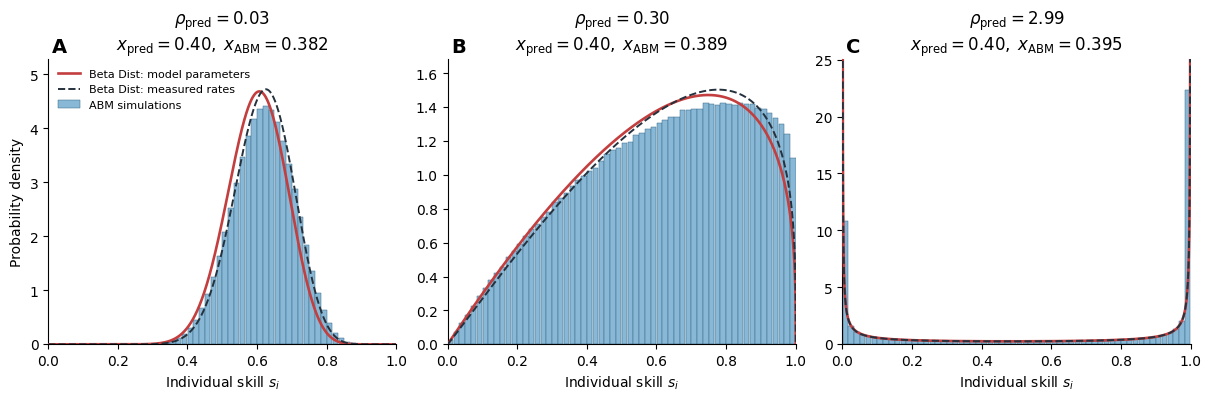

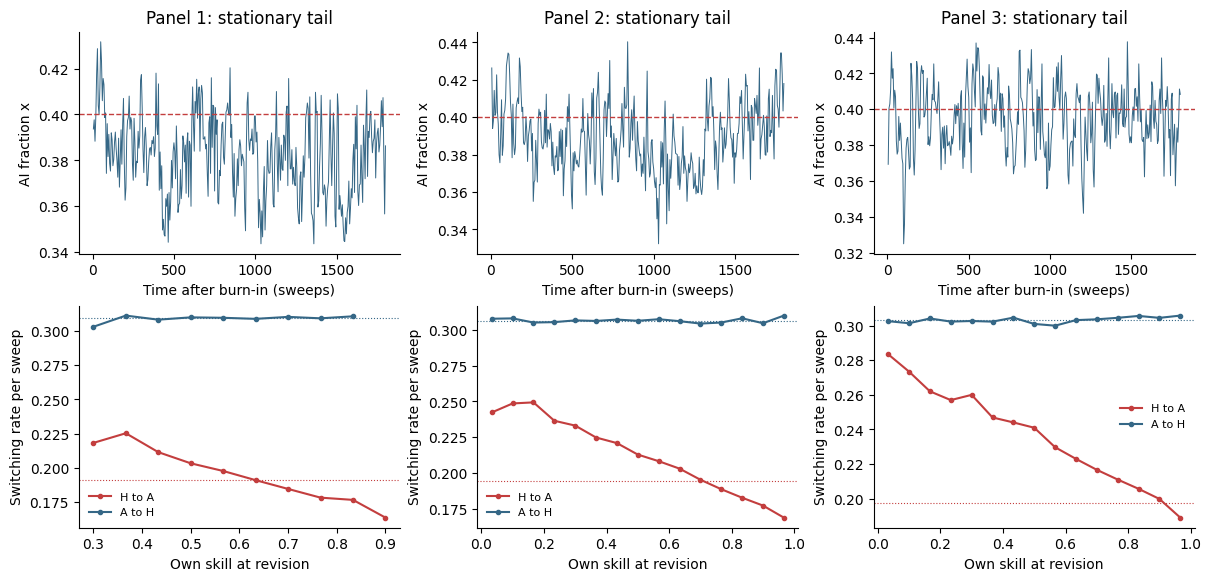


All outputs saved in /content/beta_comparison_output
TV is a binned descriptive distance (0 = agreement). CDF_edge is not a full KS test.
Repeated agents and times are correlated: no independent-sample p-values are reported.


In [ ]:
#####################à
#FIGURE 3
###################
from pathlib import Path
import sys
import subprocess
import json
import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist
from scipy.optimize import brentq
try:
    from numba import njit
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "numba"])
    from numba import njit

# ---------------------------- EDIT HERE ----------------------------
X_TARGET = 0.40                # Try 0.60 for the opposite asymmetry.
EPS_VALUES = [0.03, 0.30, 3.0] # Narrow, broad, and two endpoint peaks.
B = 1.0
C = 1.2
ETA = 0.0
BETA_SEL = 1.0                # Selection intensity, NOT a Beta shape parameter.
TIME_UNITS = "manuscript"     # Or "sweep"; see conversion below.
M = 0.002                    # Used only with TIME_UNITS="manuscript".
MU_SWEEP = 0.002             # Used only with TIME_UNITS="sweep".
N = 3000
K_SAMPLE = 50
D_OVERLAP = 0.5              # Same sampled-crowding rule as the supplied code.
N_BINS = 60
SEED = 420
SAMPLE_EVERY = 5.0           # Sweeps between histogram snapshots.
DURATION_MULTIPLIER = 1.0    # Increase to test convergence.
SHOW_MEASURED_BETA = True
OUTPUT_DIR = Path("beta_comparison_output")
# -------------------------------------------------------------------


def conventions():
    if not (0 < X_TARGET < 1 and 0 <= ETA < 1):
        raise ValueError("Require 0 < X_TARGET < 1 and 0 <= ETA < 1.")
    if BETA_SEL <= 0 or min(EPS_VALUES) <= 0:
        raise ValueError("BETA_SEL and all epsilon values must be positive.")
    if C <= B * (1 - ETA):
        raise ValueError("This targeting routine assumes C > B*(1-ETA), so the "
                         "closure has one equilibrium. Bistable cases need branch selection.")
    if N < 2 or K_SAMPLE < 1 or not (0 < D_OVERLAP <= 1):
        raise ValueError("Invalid population size, crowding sample size, or overlap.")
    if TIME_UNITS == "manuscript":
        mu = M * (BETA_SEL / 2) / (1 + M * (BETA_SEL / 2))
    elif TIME_UNITS == "sweep":
        mu = MU_SWEEP
    else:
        raise ValueError("TIME_UNITS must be 'manuscript' or 'sweep'.")
    if not 0 < mu < 1:
        raise ValueError("Require 0 < exploration probability < 1.")
    factor = (1 - mu) * BETA_SEL / 2
    return mu, factor, mu / factor


def theory_rate_sum(x, mu):
    # Rates per sweep, from the new theory note (including exploration term).
    return (1 - mu) / 2 + 2 * mu + mu * (1 - 2*x)**2 / (2*x*(1-x))


def target_intercept(eps_sweep, mu, m):
    rho = eps_sweep / theory_rate_sum(X_TARGET, mu)
    h = 1 - (1 - ETA) * X_TARGET / (1 + rho)
    return C * X_TARGET + B * h - m * (1 - 2*X_TARGET)/(X_TARGET*(1-X_TARGET))


def predict_from_parameters(a, eps_sweep, mu, m):
    def residual(x):
        rho = eps_sweep / theory_rate_sum(x, mu)
        h = 1 - (1 - ETA) * x / (1 + rho)
        return x*(1-x)*(a - C*x - B*h) + m*(1-2*x)
    x = brentq(residual, 1e-10, 1-1e-10)
    lam = theory_rate_sum(x, mu)
    rho = eps_sweep / lam
    return dict(x=x, rho=rho, lam=lam, p=(1-x)/rho, q=x/rho,
                h=1-(1-ETA)*x/(1+rho),
                g=ETA+(1-ETA)*(1-x)/(1+rho))


@njit
def simulate(n, a, b, c, eta, beta_sel, mu, eps, k, overlap,
             burn, tail, sample_every, nbins, x0, seed):
    """Continuous-time Fermi revisions at rate 1 per agent per sweep.

    Exact skill evolution between revisions; lazy updates avoid moving all N
    skills at each event. Self-comparison is a null event, as in the input code.
    Histogram snapshots are equally spaced in physical time, not event count.
    """
    np.random.seed(seed)
    z = np.zeros(n, dtype=np.int8)
    z[:int(round(n*x0))] = 1
    np.random.shuffle(z)
    s = np.ones(n)
    last = np.zeros(n)
    n_a = int(z.sum())
    nsamples = int(np.floor(tail / sample_every))
    hist = np.zeros((nsamples, nbins), dtype=np.int64)
    obs = np.zeros((nsamples, 4))  # x, mean skill, h, g
    nhaz = 15
    attempts = np.zeros((2, nhaz), dtype=np.int64)
    switches = np.zeros((2, nhaz), dtype=np.int64)
    total_switches = np.zeros(2, dtype=np.int64)
    exposure = np.zeros(2)         # Integrated number of agents in each state.
    previous_event = 0.0
    next_event = np.random.exponential(1.0/n)

    for sample in range(nsamples):
        ts = burn + (sample + 1) * sample_every
        while next_event <= ts:
            t = next_event
            # Exact person-time denominators for per-capita transition rates.
            dt_tail = max(0.0, t - max(previous_event, burn))
            exposure[0] += (n-n_a) * dt_tail
            exposure[1] += n_a * dt_tail
            i = np.random.randint(n)
            old = z[i]
            theta = eta if old else 1.0
            s[i] = theta + (s[i]-theta) * np.exp(-eps*(t-last[i]))
            last[i] = t
            hi = min(nhaz-1, max(0, int((s[i]-eta)/(1-eta)*nhaz)))
            in_tail = t >= burn
            if in_tail:
                attempts[old, hi] += 1

            flip = False
            if np.random.random() < mu:
                flip = True
            else:
                j = np.random.randint(n)
                if z[j] != old:
                    theta_j = eta if z[j] else 1.0
                    s[j] = theta_j + (s[j]-theta_j)*np.exp(-eps*(t-last[j]))
                    last[j] = t
                    crowd = np.random.binomial(k, (n_a/n)*overlap)/(k*overlap)
                    payoff_a = a - c*crowd
                    delta = b*s[j]-payoff_a if old else payoff_a-b*s[i]
                    arg = min(60.0, max(-60.0, beta_sel*delta))
                    flip = np.random.random() < 1/(1+np.exp(-arg))
            if flip:
                z[i] = 1-old
                n_a += 1 if old == 0 else -1
                if in_tail:
                    total_switches[old] += 1
                    switches[old, hi] += 1
            previous_event = t
            next_event = t + np.random.exponential(1.0/n)

        sh = 0.0
        sa = 0.0
        for i in range(n):
            theta = eta if z[i] else 1.0
            s[i] = theta + (s[i]-theta)*np.exp(-eps*(ts-last[i]))
            last[i] = ts
            bi = min(nbins-1, max(0, int((s[i]-eta)/(1-eta)*nbins)))
            hist[sample, bi] += 1
            if z[i]:
                sa += s[i]
            else:
                sh += s[i]
        obs[sample, 0] = n_a/n
        obs[sample, 1] = (sh+sa)/n
        obs[sample, 2] = sh/(n-n_a) if n_a < n else np.nan
        obs[sample, 3] = sa/n_a if n_a else np.nan

    end = burn + nsamples*sample_every
    dt_tail = max(0.0, end-max(previous_event, burn))
    exposure[0] += (n-n_a)*dt_tail
    exposure[1] += n_a*dt_tail
    return hist, obs, total_switches, exposure, attempts, switches, s, z


def beta_bin_masses(edges_u, p, q):
    # Use the survival function near 1 to avoid subtracting two numbers near 1.
    lo, hi = edges_u[:-1], edges_u[1:]
    cdf_mass = beta_dist.cdf(hi, p, q) - beta_dist.cdf(lo, p, q)
    sf_mass = beta_dist.sf(lo, p, q) - beta_dist.sf(hi, p, q)
    return np.where(lo > p/(p+q), sf_mass, cdf_mass)


def distances(mass, predicted):
    return dict(TV=float(0.5*np.abs(mass-predicted).sum()),
                CDF=float(np.max(np.abs(np.cumsum(mass-predicted)))))


def run_all():
    mu, factor, m = conventions()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Units: {TIME_UNITS}; mu={mu:.7f}; m={m:.7f}; tau={factor:.7f}*t_sweep", flush=True)
    print("Theoretical x* is targeted; measured x is allowed to differ.", flush=True)
    print("First run includes Numba compilation. Blue bars always come from the ABM.", flush=True)
    edges_u = np.linspace(0, 1, N_BINS+1)
    edges = ETA + (1-ETA)*edges_u
    rows, runs = [], []
    for j, eps_input in enumerate(EPS_VALUES):
        eps_sweep = eps_input*factor if TIME_UNITS == "manuscript" else eps_input
        a = target_intercept(eps_sweep, mu, m)
        theory = predict_from_parameters(a, eps_sweep, mu, m)
        burn = DURATION_MULTIPLIER * max(600.0, 25/eps_sweep, 100/factor)
        tail = DURATION_MULTIPLIER * max(1800.0, 25/eps_sweep, 150/factor)
        print(f"\nPanel {j+1}: a={a:.6f}, eps_input={eps_input:g}, "
              f"eps_sweep={eps_sweep:.6f}, predicted rho={theory['rho']:.4f}; "
              f"burn={burn:.0f}, tail={tail:.0f} sweeps", flush=True)
        start = time.perf_counter()
        raw = simulate(N, a, B, C, ETA, BETA_SEL, mu, eps_sweep, K_SAMPLE,
                       D_OVERLAP, burn, tail, SAMPLE_EVERY, N_BINS, X_TARGET, SEED+j)
        hist, obs, counts, exposure, attempts, switches, s, z = raw
        if np.any(exposure == 0) or np.any(counts == 0):
            raise RuntimeError("Insufficient transitions in the recording period.")
        r_plus, r_minus = counts/exposure
        measured_p, measured_q = r_minus/eps_sweep, r_plus/eps_sweep
        mass = hist.sum(axis=0)/hist.sum()
        theory_mass = beta_bin_masses(edges_u, theory['p'], theory['q'])
        measured_mass = beta_bin_masses(edges_u, measured_p, measured_q)
        assert np.isclose(mass.sum(), 1) and np.isclose(theory_mass.sum(), 1)
        half = len(obs)//2
        # Descriptive stationarity diagnostics, not significance tests.
        dx_tail = obs[half:, 0].mean()-obs[:half, 0].mean()
        hist_halves_tv = 0.5*np.abs(hist[:half].sum(axis=0)/hist[:half].sum()
                                  - hist[half:].sum(axis=0)/hist[half:].sum()).sum()
        x_time = exposure[1]/exposure.sum()
        row = dict(panel=j+1, eps_input=eps_input, eps_sweep=eps_sweep, a=a,
                   mu=mu, m=m, x_pred=theory['x'], x_ABM=x_time,
                   rho_pred=theory['rho'], rho_measured=eps_sweep/(r_plus+r_minus),
                   p_pred=theory['p'], q_pred=theory['q'],
                   r_plus=r_plus, r_minus=r_minus, p_measured=measured_p, q_measured=measured_q,
                   mean_pred=1-(1-ETA)*theory['x'], mean_ABM=obs[:,1].mean(),
                   h_pred=theory['h'], h_ABM=np.nanmean(obs[:,2]),
                   g_pred=theory['g'], g_ABM=np.nanmean(obs[:,3]),
                   TV_theory=distances(mass,theory_mass)['TV'],
                   TV_measured=distances(mass,measured_mass)['TV'],
                   CDF_edge_theory=distances(mass,theory_mass)['CDF'],
                   tail_dx=dx_tail, tail_hist_TV=hist_halves_tv,
                   mean_balance_error=obs[:,1].mean()-(1-(1-ETA)*x_time),
                   burn_sweeps=burn, tail_sweeps=len(obs)*SAMPLE_EVERY)
        rows.append(row)
        runs.append(dict(row=row, theory=theory, mass=mass, theory_mass=theory_mass,
                         measured_mass=measured_mass, obs=obs, attempts=attempts, switches=switches))
        np.savez_compressed(OUTPUT_DIR/f"panel_{j+1}_data.npz", edges=edges,
                            histogram_counts=hist, observables=obs,
                            switching_counts=counts, person_time=exposure,
                            hazard_attempts=attempts, hazard_switches=switches,
                            final_skills=s, final_workflows=z)
        print(f"  x: predicted {theory['x']:.4f}, ABM {x_time:.4f}; "
              f"TV: theory {row['TV_theory']:.4f}, measured rates {row['TV_measured']:.4f}", flush=True)
        print(f"  Tail half differences: dx={dx_tail:+.4f}, histogram TV={hist_halves_tv:.4f}; "
              f"elapsed {time.perf_counter()-start:.1f}s", flush=True)
        if abs(dx_tail) > 0.025 or hist_halves_tv > 0.05:
            print("  Check stationarity: increase DURATION_MULTIPLIER and compare another SEED.", flush=True)

    # Main figure: smooth analytical PDFs over the agent histogram bars.
    # Bin-integrated probabilities above remain the basis of all metrics.
    plt.rcParams.update({"font.size":10, "axes.spines.top":False,
                         "axes.spines.right":False, "pdf.fonttype":42})
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), constrained_layout=True)
    centres = (edges[:-1]+edges[1:])/2
    width = np.diff(edges)
    # Avoid exactly 0 and 1, where U-shaped Beta PDFs diverge.
    near_endpoint = np.geomspace(1e-8, 0.02, 500)
    smooth_u = np.unique(np.concatenate((np.linspace(1e-6, 1-1e-6, 6000),
                                         near_endpoint, 1-near_endpoint)))
    smooth_s = ETA + (1-ETA)*smooth_u
    for j, (ax, run) in enumerate(zip(axes, runs)):
        row, th = run['row'], run['theory']
        ax.bar(centres, run['mass']/width, width=0.94*width,
               color="#89b8d6", edgecolor="#356786", linewidth=0.35,
               label="ABM simulations", zorder=1)
        ax.plot(smooth_s, beta_dist.pdf(smooth_u, th['p'], th['q'])/(1-ETA),
                color="#c33e3e", linewidth=1.9, label="Beta Dist: model parameters", zorder=3)
        if SHOW_MEASURED_BETA:
            ax.plot(smooth_s, beta_dist.pdf(smooth_u, row['p_measured'],
                                           row['q_measured'])/(1-ETA),
                    color="#25313d", linestyle="--", linewidth=1.4,
                    label="Beta Dist: measured rates", zorder=4)
        # Endpoint divergences extend above the frame; do not let them
        # compress all histogram bars through automatic y-axis scaling.
        ymax = 1.12 * max(np.max(run['mass']/width),
                          np.max(run['theory_mass']/width),
                          np.max(run['measured_mass']/width) if SHOW_MEASURED_BETA else 0)
        ax.set(xlim=(ETA,1), ylim=(0,ymax), xlabel=r"Individual skill $s_i$")
        ax.text( 0.01, 1.025, chr(65 + j), transform=ax.transAxes, fontsize=14, fontweight="bold")
        ax.set_title( rf"$\rho_{{\rm pred}}={th['rho']:.2f}$"
                   + "\n"
                   + rf"$x_{{\rm pred}}={th['x']:.2f},\;x_{{\rm ABM}}={row['x_ABM']:.3f}$"
                    )
        # ax.set_title(f"({chr(97+j)})  " + rf"$\rho_{{\rm pred}}={th['rho']:.2f}$"
        #              + "\n" + rf"$x_{{\rm pred}}={th['x']:.2f},\;x_{{\rm ABM}}={row['x_ABM']:.3f}$")
        if j == 0:
            ax.set_ylabel("Probability density")
            ax.legend(frameon=False, fontsize=8, loc="upper left")
    fig.savefig(OUTPUT_DIR/"fermi_beta_three_panels.png", dpi=220)
    fig.savefig(OUTPUT_DIR/"fermi_beta_three_panels.pdf", bbox_inches="tight")
    plt.show()

    # Separate diagnostics: stationary time traces and skill-dependent hazards.
    diagnostic, axes = plt.subplots(2, 3, figsize=(12, 5.7), constrained_layout=True)
    for j, run in enumerate(runs):
        row, obs = run['row'], run['obs']
        ts = SAMPLE_EVERY*np.arange(1,len(obs)+1)
        axes[0,j].plot(ts, obs[:,0], color="#356786", lw=0.7)
        axes[0,j].axhline(X_TARGET, color="#c33e3e", lw=1, ls="--")
        axes[0,j].set(xlabel="Time after burn-in (sweeps)", ylabel="AI fraction x",
                      title=f"Panel {j+1}: stationary tail")
        for workflow, color, label, overall in [(0,"#c33e3e","H to A",row['r_plus']),
                                               (1,"#356786","A to H",row['r_minus'])]:
            attempt = run['attempts'][workflow]
            rate = np.divide(run['switches'][workflow], attempt,
                             out=np.full(len(attempt), np.nan), where=attempt>500)
            cc = ETA+(1-ETA)*(np.arange(len(attempt))+0.5)/len(attempt)
            axes[1,j].plot(cc,rate,"o-",ms=3,color=color,label=label)
            axes[1,j].axhline(overall,color=color,lw=0.8,ls=":")
        axes[1,j].set(xlabel="Own skill at revision",ylabel="Switching rate per sweep")
        axes[1,j].legend(frameon=False,fontsize=8)
    diagnostic.savefig(OUTPUT_DIR/"fermi_beta_diagnostics.png", dpi=180)
    plt.show()

    with open(OUTPUT_DIR/"comparison_summary.csv", "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    configuration = dict(X_TARGET=X_TARGET, EPS_VALUES=EPS_VALUES, B=B,C=C,ETA=ETA,
                         BETA_SEL=BETA_SEL,TIME_UNITS=TIME_UNITS,M=M,MU_SWEEP=MU_SWEEP,
                         N=N,K_SAMPLE=K_SAMPLE,D_OVERLAP=D_OVERLAP,N_BINS=N_BINS,SEED=SEED,
                         SAMPLE_EVERY=SAMPLE_EVERY,DURATION_MULTIPLIER=DURATION_MULTIPLIER)
    with open(OUTPUT_DIR/"configuration.json", "w") as f:
        json.dump(configuration,f,indent=2)
    print("\nAll outputs saved in", OUTPUT_DIR.resolve())
    print("TV is a binned descriptive distance (0 = agreement). CDF_edge is not a full KS test.")
    print("Repeated agents and times are correlated: no independent-sample p-values are reported.")
    return runs


if __name__ == "__main__":
    results = run_all()


###Figure 4

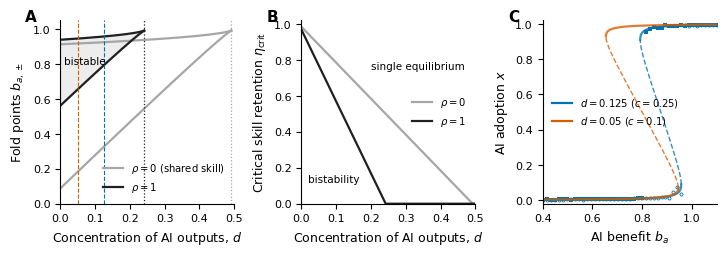

d=0.125: folds rho=0 [0.3253506783667386, 0.9246493216332614], rho=1.0 [0.7925243789814849, 0.9574756210185151]
d=0.05: folds rho=0 [0.18275380489236434, 0.9172461951076356], rho=1.0 [0.6544161223934748, 0.9455838776065252]


In [ ]:
# ================================================================
# FIGURE 4 — DIVERSIFYING AI OUTPUT (theory + optional ABM overlay)
# Theory panels A-C; panel C overlays agent-based loops if the
# checkpoints of the Fig. 2 cell exist for c = 0.25 and c = 0.10.
# ================================================================
import pickle
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

BH, ETA, M, OMEGA = 1.0, 0.0, 0.002, 2.0
RHO_C = 1.0                        # rho of panel C (epsilon = 2, beta = 0.5)
D_REF, D_DIV = 0.125, 0.05         # c = 0.25 and c = 0.10
CKPT_DIR = Path("/content/drive/MyDrive/PNAS_private_skill_hysteresis")
CKPT = {D_REF: CKPT_DIR / "runs_N4000_beta0.5_c0.25.pkl",
        D_DIV: CKPT_DIR / "runs_N4000_beta0.5_c0.1.pkl"}
EPS_ABM = 2.0

BLUE, ORANGE, BLACK, GRAY = "#0072B2", "#D55E00", "#202020", "#A6A6A6"
plt.rcParams.update({"font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "legend.fontsize": 7.2, "axes.spines.top": False,
    "axes.spines.right": False, "pdf.fonttype": 42})
X = np.linspace(0.0025, 0.9975, 8000)

def gamma(d, rho): return BH * (1 - ETA) / (1 + rho) - OMEGA * d
def ba_curve(x, d, rho): return BH - gamma(d, rho) * x + M * (2 * x - 1) / (x * (1 - x))
def folds(d, rho):
    if gamma(d, rho) <= 8 * M: return None
    aa = ba_curve(X, d, rho); da = np.diff(aa)
    idx = np.where(np.sign(da[:-1]) != np.sign(da[1:]))[0] + 1
    out = []
    for i in (idx[0], idx[-1]):
        s = -1 if aa[i] > aa[i - 1] else 1
        r = minimize_scalar(lambda x: s * ba_curve(x, d, rho),
                            bounds=(X[max(i - 3, 0)], X[min(i + 3, len(X) - 1)]), method="bounded")
        out.append(float(ba_curve(r.x, d, rho)))
    return sorted(out)

D = np.linspace(0, 0.5, 600)
fig, ax = plt.subplots(1, 3, figsize=(7.15, 2.45), constrained_layout=True)

# A: folds vs d
for rho, col, lab in ((0.0, GRAY, r"$\rho=0$ (shared skill)"), (RHO_C, BLACK, rf"$\rho={RHO_C:g}$")):
    fl = [folds(d, rho) for d in D]
    lo = np.array([np.nan if f is None else f[0] for f in fl])
    hi = np.array([np.nan if f is None else f[1] for f in fl])
    ax[0].plot(D, lo, color=col, lw=1.6, label=lab); ax[0].plot(D, hi, color=col, lw=1.6)
    if rho == RHO_C: ax[0].fill_between(D, lo, hi, color=BLACK, alpha=0.08)
    ax[0].axvline((BH * (1 - ETA) / (1 + rho) - 8 * M) / OMEGA, color=col, ls=":", lw=0.9)
for dm, col in ((D_REF, BLUE), (D_DIV, ORANGE)):
    ax[0].axvline(dm, color=col, lw=0.8, ls="--")
ax[0].text(0.012, 0.80, "bistable", fontsize=7.5)
ax[0].set_xlabel(r"Concentration of AI outputs, $d$"); ax[0].set_ylabel(r"Fold points $b_{a,\pm}$")
ax[0].set_xlim(0, 0.5); ax[0].set_ylim(0, 1.05); ax[0].legend(frameon=False, loc="lower right")

# B: critical retention vs d
for rho, col, lab in ((0.0, GRAY, r"$\rho=0$"), (RHO_C, BLACK, rf"$\rho={RHO_C:g}$")):
    ax[1].plot(D, np.clip(1 - (1 + rho) * (OMEGA * D + 8 * M) / BH, 0, 1), color=col, lw=1.6, label=lab)
ax[1].text(0.2, 0.75, "single equilibrium", fontsize=7.5)
ax[1].text(0.02, 0.12, "bistability", fontsize=7.5)
ax[1].set_xlabel(r"Concentration of AI outputs, $d$"); ax[1].set_ylabel(r"Critical skill retention $\eta_{\rm crit}$")
ax[1].set_xlim(0, 0.5); ax[1].set_ylim(0, 1.02); ax[1].legend(frameon=False)

# C: equilibrium curves at rho = RHO_C, with optional ABM loops
for d, col in ((D_REF, BLUE), (D_DIV, ORANGE)):
    aa = ba_curve(X, d, RHO_C); stable = np.gradient(aa, X) > 0
    for mask, ls, lw in ((stable, "-", 1.6), (~stable, "--", 1.0)):
        idx = np.where(mask)[0]
        for g in np.split(idx, np.where(np.diff(idx) > 1)[0] + 1):
            ax[2].plot(aa[g], X[g], color=col, ls=ls, lw=lw, alpha=0.8)
    ax[2].plot([], [], color=col, lw=1.6, label=rf"$d={d:g}$ ($c={OMEGA*d:g}$)")
    if CKPT[d].exists():
        runs = pickle.load(open(CKPT[d], "rb"))[EPS_ABM][0]
        ax[2].plot(runs["up"]["a"], runs["up"]["x"], "o", ms=2.2, color=col, mfc="none", mew=0.6)
        ax[2].plot(runs["down"]["a"], runs["down"]["x"], "s", ms=2.2, color=col, mew=0)
ax[2].set_xlabel(r"AI benefit $b_a$"); ax[2].set_ylabel(r"AI adoption $x$")
ax[2].set_xlim(0.4, 1.1); ax[2].set_ylim(-0.02, 1.02); ax[2].legend(frameon=False, loc="center left")

for lab, a in zip("ABC", ax):
    a.text(-0.2, 1.06, lab, transform=a.transAxes, fontsize=11, fontweight="bold", va="top")
fig.savefig("fig4.pdf", bbox_inches="tight"); fig.savefig("fig4.png", dpi=300, bbox_inches="tight")
plt.show()
for d in (D_REF, D_DIV):
    print(f"d={d}: folds rho=0 {folds(d,0.0)}, rho={RHO_C} {folds(d,RHO_C)}")


#SI Figures

###Fig Finite Scaling

Mounted at /content/drive
eps=2.0 N=500 rep 1: b_a+=0.9379 b_a-=0.8348  (theory 0.9573, 0.7911) [0.3 min, saved]
eps=2.0 N=500 rep 2: b_a+=0.9379 b_a-=0.8224  (theory 0.9573, 0.7911) [0.1 min, saved]
eps=2.0 N=500 rep 3: b_a+=0.9510 b_a-=0.8314  (theory 0.9573, 0.7911) [0.1 min, saved]
eps=2.0 N=1000 rep 1: b_a+=0.9511 b_a-=0.8099  (theory 0.9573, 0.7911) [0.1 min, saved]
eps=2.0 N=1000 rep 2: b_a+=0.9385 b_a-=0.8229  (theory 0.9573, 0.7911) [0.1 min, saved]
eps=2.0 N=1000 rep 3: b_a+=0.9628 b_a-=0.7974  (theory 0.9573, 0.7911) [0.1 min, saved]
eps=2.0 N=2000 rep 1: b_a+=0.9384 b_a-=0.7977  (theory 0.9573, 0.7911) [0.2 min, saved]
eps=2.0 N=2000 rep 2: b_a+=0.9508 b_a-=0.7976  (theory 0.9573, 0.7911) [0.2 min, saved]
eps=2.0 N=2000 rep 3: b_a+=0.9635 b_a-=0.8224  (theory 0.9573, 0.7911) [0.2 min, saved]
eps=2.0 N=4000 rep 1: b_a+=0.9634 b_a-=0.7856  (theory 0.9573, 0.7911) [0.5 min, saved]
eps=2.0 N=4000 rep 2: b_a+=0.9634 b_a-=0.8100  (theory 0.9573, 0.7911) [0.6 min, saved]
eps=2.0 N

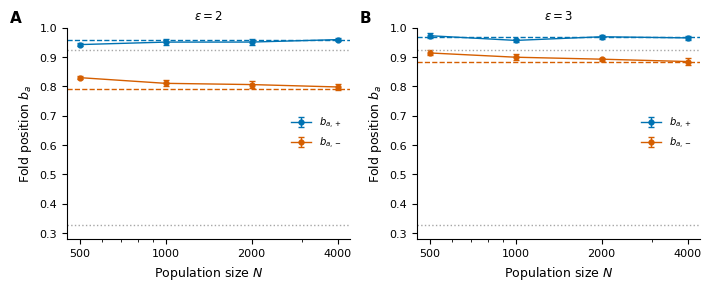


Folds (mean over repetitions):
eps=2.0 N=500: b_a+ = 0.9423 (theory 0.9573), b_a- = 0.8295 (theory 0.7911)
eps=2.0 N=1000: b_a+ = 0.9508 (theory 0.9573), b_a- = 0.8101 (theory 0.7911)
eps=2.0 N=2000: b_a+ = 0.9509 (theory 0.9573), b_a- = 0.8059 (theory 0.7911)
eps=2.0 N=4000: b_a+ = 0.9592 (theory 0.9573), b_a- = 0.7977 (theory 0.7911)
eps=3.0 N=500: b_a+ = 0.9725 (theory 0.9675), b_a- = 0.9138 (theory 0.8813)
eps=3.0 N=1000: b_a+ = 0.9565 (theory 0.9675), b_a- = 0.8992 (theory 0.8813)
eps=3.0 N=2000: b_a+ = 0.9690 (theory 0.9675), b_a- = 0.8925 (theory 0.8813)
eps=3.0 N=4000: b_a+ = 0.9651 (theory 0.9675), b_a- = 0.8844 (theory 0.8813)
Reduced-theory folds: [0.3254, 0.9246]
Files in /content/drive/MyDrive/PNAS_private_skill_hysteresis


In [ ]:
# ================================================================
# SI FIGURE S1 — FINITE-SIZE TEST OF THE FOLD POSITIONS
# (same model and conventions as Fig. 2).
#
# For each epsilon in FS_EPS and each N in FS_N, the two folds are measured
# with local quasi-static sweeps around the Gamma_eff predictions:
#   upper fold: increasing b_a, starting from a mostly autonomous population
#   lower fold: decreasing b_a, starting from a mostly AI-reliant, deskilled one
# A fold is located where the branch crosses x = 1/2.
# Results are saved (Google Drive when available) after every repetition,
# so the cell can be rerun to resume. PLOT_ONLY = True redraws from saved data.
# ================================================================

import sys, subprocess, time, csv, pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

try:
    from numba import njit
except ImportError:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numba"])
        from numba import njit
    except Exception:
        print("numba unavailable: pure Python (slow; use SMOKE_TEST).")
        def njit(f=None, **kw):
            return f if f is not None else (lambda g: g)

# ---------------- parameters ----------------
SMOKE_TEST = False
PLOT_ONLY = False

B, C, ETA, M, BETA_SEL = 1.0, 0.25, 0.0, 0.002, 0.5
K_SAMPLE = 50
FS_EPS = [2.0, 3.0]
FS_N = [500, 1000, 2000, 4000]
FS_REPS = 3
FS_INSIDE, FS_BEYOND, FS_DA = 0.15, 0.05, 0.0125   # sweep window and step in b_a
EQUIL_SWEEPS, SAMPLE_SWEEPS, SAMPLE_EVERY = 1200.0, 300.0, 5.0
SEED = 777

if SMOKE_TEST:
    FS_EPS, FS_N, FS_REPS, FS_DA = [2.0], [40, 80], 1, 0.05
    EQUIL_SWEEPS, SAMPLE_SWEEPS = 20.0, 10.0

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/PNAS_private_skill_hysteresis")
except ImportError:
    OUT = Path("PNAS_private_skill_hysteresis")
OUT.mkdir(parents=True, exist_ok=True)
CKPT = OUT / f"finite_size_beta{BETA_SEL}_c{C}.pkl"

# ---------------- units ----------------
w = BETA_SEL / 2.0
MU = M * w / (1.0 + M * w)
TIME_FACTOR = (1.0 - MU) * w
DELTA = 1.0 - ETA

# ---------------- theory (Gamma_eff) ----------------
def lambda_sweep(x):
    x = np.asarray(x, dtype=float)
    return (1 - MU) / 2 + 2 * MU + MU * (1 - 2 * x) ** 2 / (2 * x * (1 - x))

def a_eff(x, eps):
    x = np.asarray(x, dtype=float)
    rho = eps * TIME_FACTOR / lambda_sweep(x)
    G = B * DELTA / (1 + rho) - C
    return B - G * x + M * (2 * x - 1) / (x * (1 - x))

def a_shared(x):
    x = np.asarray(x, dtype=float)
    return B - (B * DELTA - C) * x + M * (2 * x - 1) / (x * (1 - x))

XG = np.linspace(0.0025, 0.9975, 7000)
def folds_of(curve):
    aa = curve(XG); da = np.diff(aa)
    idx = np.where(np.sign(da[:-1]) != np.sign(da[1:]))[0] + 1
    if len(idx) < 2:
        return None
    vals = []
    for i in (idx[0], idx[-1]):
        s = -1.0 if aa[i] > aa[i - 1] else 1.0
        r = minimize_scalar(lambda xx, s=s: s * float(curve(xx)),
                            bounds=(XG[max(i - 3, 0)], XG[min(i + 3, len(XG) - 1)]),
                            method="bounded", options={"xatol": 1e-10})
        vals.append(float(curve(r.x)))
    return sorted(vals)            # [b_a-, b_a+]

SHARED = folds_of(a_shared)

# ---------------- agent-based model ----------------
@njit
def init_pop(n, x0, sA, seed):
    np.random.seed(seed)
    z = np.zeros(n, dtype=np.int8); nA = int(round(n * x0)); z[:nA] = 1
    np.random.shuffle(z)
    s = np.ones(n)
    for i in range(n):
        if z[i] == 1:
            s[i] = sA
    return z, s, np.zeros(n), nA

@njit
def upd(i, z, s, last, t, eta, e):
    tg = eta if z[i] == 1 else 1.0
    s[i] = tg + (s[i] - tg) * np.exp(-e * (t - last[i])); last[i] = t

@njit
def event(z, s, last, nA, t, a, b, c, eta, beta, mu, e, k):
    n = z.size; i = np.random.randint(n); old = z[i]
    upd(i, z, s, last, t, eta, e); flip = False
    if np.random.random() < mu:
        flip = True
    else:
        j = np.random.randint(n)
        if z[j] != old:
            upd(j, z, s, last, t, eta, e)
            piA = a - c * np.random.binomial(k, nA / n) / k
            dpi = piA - b * s[i] if old == 0 else b * s[j] - piA
            arg = min(60.0, max(-60.0, beta * dpi))
            if np.random.random() < 1.0 / (1.0 + np.exp(-arg)):
                flip = True
    if flip:
        z[i] = 1 - old
        nA += 1 if old == 0 else -1
    return nA

@njit
def branch_x(avals, z, s, last, nA, b, c, eta, beta, mu, e, k, teq, tms, tev, seed):
    np.random.seed(seed)
    n = z.size; t = 0.0; nxt = np.random.exponential(1.0 / n)
    out = np.empty(avals.size)
    for ia in range(avals.size):
        a = avals[ia]; tend = t + teq
        while nxt <= tend:
            nA = event(z, s, last, nA, nxt, a, b, c, eta, beta, mu, e, k)
            nxt += np.random.exponential(1.0 / n)
        t = tend; acc = 0.0; ns = int(tms / tev)
        for q in range(ns):
            ts = t + (q + 1) * tev
            while nxt <= ts:
                nA = event(z, s, last, nA, nxt, a, b, c, eta, beta, mu, e, k)
                nxt += np.random.exponential(1.0 / n)
            acc += nA / n
        t = t + ns * tev
        out[ia] = acc / ns
    return out

def crossing(avals, xs, increasing):
    hit = np.where(xs >= 0.5)[0] if increasing else np.where(xs <= 0.5)[0]
    if len(hit) == 0 or hit[0] == 0:
        return np.nan
    k = hit[0]
    return float(avals[k-1] + (0.5 - xs[k-1]) * (avals[k] - avals[k-1]) / (xs[k] - xs[k-1]))

# ---------------- run (resumable) ----------------
FS = pickle.load(open(CKPT, "rb")) if CKPT.exists() else {}
if not PLOT_ONLY:
    t0 = time.perf_counter()
    for eps in FS_EPS:
        lo, hi = folds_of(lambda x: a_eff(x, eps))
        a_up = np.arange(hi - FS_INSIDE, hi + FS_BEYOND + 1e-9, FS_DA)
        a_dn = np.arange(lo + FS_INSIDE, lo - FS_BEYOND - 1e-9, -FS_DA)
        for n in FS_N:
            key = (eps, n)
            FS.setdefault(key, {"up": [], "down": []})
            for rep in range(len(FS[key]["up"]), FS_REPS):
                base = SEED + 1000 * rep + 13 * n + int(100 * eps)
                tr = time.perf_counter()
                z, s, last, nA = init_pop(n, 0.01, 1.0, base)
                xu = branch_x(a_up, z, s, last, nA, B, C, ETA, BETA_SEL, MU,
                              eps * TIME_FACTOR, K_SAMPLE, EQUIL_SWEEPS, SAMPLE_SWEEPS,
                              SAMPLE_EVERY, base + 1)
                z, s, last, nA = init_pop(n, 0.99, ETA, base + 2)
                xd = branch_x(a_dn, z, s, last, nA, B, C, ETA, BETA_SEL, MU,
                              eps * TIME_FACTOR, K_SAMPLE, EQUIL_SWEEPS, SAMPLE_SWEEPS,
                              SAMPLE_EVERY, base + 3)
                FS[key]["up"].append(crossing(a_up, xu, True))
                FS[key]["down"].append(crossing(a_dn, xd, False))
                pickle.dump(FS, open(CKPT, "wb"))
                print(f"eps={eps} N={n} rep {rep+1}: b_a+={FS[key]['up'][-1]:.4f} "
                      f"b_a-={FS[key]['down'][-1]:.4f}  (theory {hi:.4f}, {lo:.4f}) "
                      f"[{(time.perf_counter()-tr)/60:.1f} min, saved]", flush=True)
    print(f"Total: {(time.perf_counter()-t0)/60:.1f} min")

with open(OUT / "finite_size_folds.csv", "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["epsilon", "N", "rep", "b_a_plus", "b_a_minus"])
    for (e, n), d in sorted(FS.items()):
        for r, (u, dn) in enumerate(zip(d["up"], d["down"])):
            wr.writerow([e, n, r, u, dn])

# ---------------- figure ----------------
BLUE, ORANGE, GRAY = "#0072B2", "#D55E00", "#A6A6A6"
plt.rcParams.update({"font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.fontsize": 7.2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42})
eps_list = sorted({e for (e, _) in FS})
fig, axs = plt.subplots(1, len(eps_list), figsize=(3.5 * len(eps_list), 2.8),
                        constrained_layout=True, squeeze=False)
for ax, e in zip(axs[0], eps_list):
    lo, hi = folds_of(lambda x: a_eff(x, e))
    ns = sorted(n for (ee, n) in FS if ee == e)
    for key_, col, lab, th in (("up", BLUE, r"$b_{a,+}$", hi), ("down", ORANGE, r"$b_{a,-}$", lo)):
        v = [np.array(FS[(e, n)][key_], dtype=float) for n in ns]
        ax.errorbar(ns, [np.nanmean(x) for x in v], yerr=[np.nanstd(x) for x in v],
                    fmt="o-", color=col, ms=3.5, lw=1.0, capsize=2, label=lab)
        ax.axhline(th, color=col, ls="--", lw=1.0)
    if SHARED is not None:
        for aa in SHARED:
            ax.axhline(aa, color=GRAY, ls=":", lw=1.0)
    ax.set_xscale("log")
    ax.set_xticks(ns); ax.set_xticklabels([str(n) for n in ns])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel(r"Population size $N$"); ax.set_ylabel(r"Fold position $b_a$")
    ax.set_title(rf"$\varepsilon={e:g}$", fontsize=8.5)
    ax.set_ylim(0.28, 1.0)
    ax.legend(frameon=False, loc="center right")
for lab, ax in zip("AB", axs[0]):
    ax.text(-0.2, 1.08, lab, transform=ax.transAxes, fontsize=11, fontweight="bold", va="top")
fig.savefig(OUT / "SI_finite_size_folds.pdf", bbox_inches="tight")
fig.savefig(OUT / "SI_finite_size_folds.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nFolds (mean over repetitions):")
for (e, n), d in sorted(FS.items()):
    lo, hi = folds_of(lambda x: a_eff(x, e))
    print(f"eps={e} N={n}: b_a+ = {np.nanmean(d['up']):.4f} (theory {hi:.4f}), "
          f"b_a- = {np.nanmean(d['down']):.4f} (theory {lo:.4f})")
print("Reduced-theory folds:", [round(v, 4) for v in SHARED])
print("Files in", OUT.resolve())


###Crowding figures

In [ ]:
# [setup] Run this cell once before any figure cell.
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.optimize import brentq, minimize_scalar
from scipy.integrate import solve_ivp
from scipy.stats import binom

os.makedirs('figures-SI', exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'pdf.fonttype': 42, 'savefig.bbox': 'tight'})
B_H, ETA, EPS, M = 1.0, 0.0, 0.05, 0.002
COL = {0.5:'#ef6b3a', 1:'#777777', 1.5:'#ee77aa', 2:'#2878dd', 3:'#00aa75'}

def payoff(x, a, c, alpha, eta=ETA):
    return a-B_H+B_H*(1-eta)*x-c*np.power(x, alpha)

def payoff_prime(x, c, alpha, eta=ETA):
    return B_H*(1-eta)-c*alpha*np.power(x, alpha-1)

def ae(x, c, alpha, m=M, eta=ETA):
    return B_H-B_H*(1-eta)*x+c*np.power(x, alpha)+m*(2*x-1)/(x*(1-x))

def phi(x):
    return 1/x**2+1/(1-x)**2

def feedback(x, c, alpha, eta=ETA):
    return payoff_prime(x, c, alpha, eta)

def fold_x(c, alpha, m=M, eta=ETA):
    f = lambda x: feedback(x,c,alpha,eta)-m*phi(x)
    grid = np.linspace(1e-6, 1-1e-6, 2001)
    vals = f(grid)
    hits = np.where(vals[:-1]*vals[1:] < 0)[0]
    return [brentq(f,grid[i],grid[i+1]) for i in hits]

def stationary_roots(a,c,alpha,m=M,eta=ETA):
    f = lambda x: ae(x,c,alpha,m,eta)-a
    grid = np.linspace(1e-6,1-1e-6,2501)
    vals = f(grid)
    hits = np.where(vals[:-1]*vals[1:] < 0)[0]
    return [brentq(f,grid[i],grid[i+1]) for i in hits]

def rhs(t,y,a,c,alpha,eps=EPS,m=M):
    x,s = y
    return [x*(1-x)*(a-B_H*s-c*max(x,0)**alpha)+m*(1-2*x),
            eps*(1-(1-ETA)*x-s)]

def finish(fig, number):
    fig.savefig(f'figures-SI/gamma_fig{number}.pdf')
    fig.savefig(f'figures-SI/gamma_fig{number}.png',dpi=220)
    plt.show()



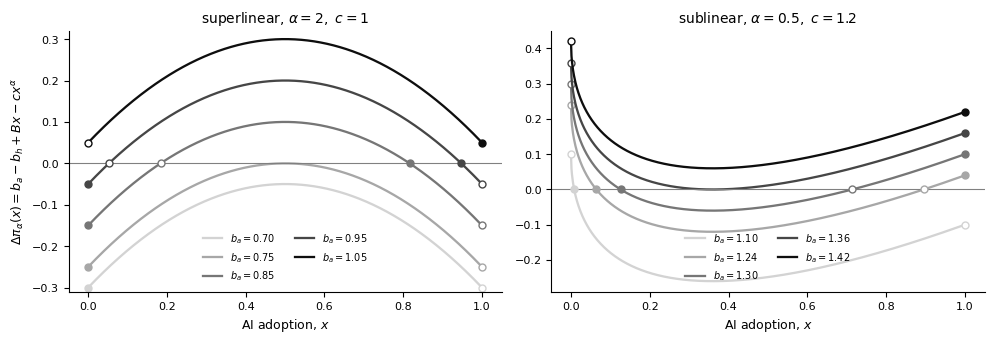

In [ ]:
# FIGURE 1 — payoff difference and equilibria, m=0
fig,axs=plt.subplots(1,2,figsize=(10,3.5),sharex=True)
configs=[(2,1,[.70,.75,.85,.95,1.05]),(.5,1.2,[1.10,1.24,1.30,1.36,1.42])]
for ax,(alpha,c,alist) in zip(axs,configs):
    x=np.linspace(0,1,801)
    shades=plt.cm.Greys(np.linspace(.28,.95,len(alist)))
    for a,color in zip(alist,shades):
        y=payoff(x,a,c,alpha)
        ax.plot(x,y,color=color,lw=1.65,label=fr'$b_a={a:.2f}$')
        # Boundary marker: filled if that boundary is stable.
        for endpoint,stable in [(0,a<B_H),(1,a>B_H*ETA+c)]:
            ax.plot(endpoint,payoff(endpoint,a,c,alpha),'o',ms=5,
                    mfc=color if stable else 'white',mec=color,clip_on=False)
        signs=y[:-1]*y[1:]
        for i in np.where(signs<0)[0]:
            root=brentq(lambda z:payoff(z,a,c,alpha),x[i],x[i+1])
            stable=payoff_prime(root,c,alpha)<0
            ax.plot(root,0,'o',ms=5,mfc=color if stable else 'white',mec=color,zorder=5)
    ax.axhline(0,color='0.5',lw=.8)
    ax.set_xlim(-.05,1.05)
    ax.set_xlabel(r'AI adoption, $x$')
    ax.set_title(fr"{'superlinear' if alpha>1 else 'sublinear'}, $\alpha={alpha:g},\ c={c:g}$",fontsize=10)
    ax.legend(frameon=False,ncol=2,fontsize=7,loc='lower center')
axs[0].set_ylabel(r'$\Delta\pi_\alpha(x)=b_a-b_h+B x-cx^\alpha$')
axs[0].set_ylim(-.31,.32); axs[1].set_ylim(-.29,.45)
fig.tight_layout(); finish(fig,1)



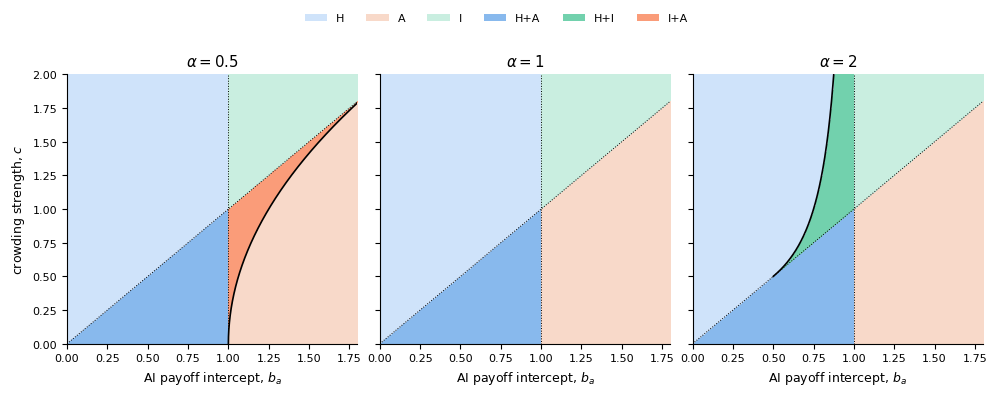

In [ ]:
# FIGURE 2 — attractor sets in the (b_a,c) plane, m=0
fig,axs=plt.subplots(1,3,figsize=(10,3.6),sharey=True)
names=['H','A','I','H+A','H+I','I+A']
colors=['#cfe3fa','#f8d9c9','#c9eee0','#88b9ed','#72d1ad','#fa9c79']
cmap=ListedColormap(colors); norm=BoundaryNorm(np.arange(-.5,6.5),6)
aa=np.linspace(0,1.8,501)[None,:]; cc=np.linspace(.001,2.0,521)[:,None]
for ax,alpha in zip(axs,[.5,1,2]):
    H=aa<B_H
    A=aa>cc+B_H*ETA
    if alpha==.5:
        disc=cc**2-4*(aa-B_H)
        yl=(cc-np.sqrt(np.maximum(disc,0)))/2
        I=(disc>0)&(yl>0)&(yl<1)&(yl<cc/2)
    elif alpha==2:
        disc=1-4*cc*(B_H-aa)
        xhi=(1+np.sqrt(np.maximum(disc,0)))/(2*cc)
        I=(disc>0)&(xhi>0)&(xhi<1)&(xhi>1/(2*cc))
    else:
        root=(aa-B_H)/(cc-B_H*(1-ETA)+1e-300)
        I=(cc>B_H*(1-ETA))&(root>0)&(root<1)
    H,A,I=np.broadcast_arrays(H,A,I)
    state=np.select([H&I,I&A,H&A,I,A], [4,5,3,2,1],default=0)
    ax.imshow(state,origin='lower',aspect='auto',interpolation='nearest',
              extent=[0,1.8,0,2],cmap=cmap,norm=norm)
    cv=np.linspace(0,2,500)
    ax.axvline(B_H,ls=':',color='k',lw=.7)
    ax.plot(cv+B_H*ETA,cv,':',color='k',lw=.7)
    if alpha!=1:
        cv2=np.linspace(.002,2,1500)
        xm=(B_H*(1-ETA)/(alpha*cv2))**(1/(alpha-1))
        ok=(xm>0)&(xm<1)
        af=B_H-(1-1/alpha)*B_H*(1-ETA)*xm
        ax.plot(af[ok],cv2[ok],color='k',lw=1.2)
    ax.set(xlim=(0,1.8),ylim=(0,2),xlabel=r'AI payoff intercept, $b_a$')
    ax.set_title(fr'$\alpha={alpha:g}$')
axs[0].set_ylabel(r'crowding strength, $c$')
fig.legend(handles=[Patch(facecolor=col,label=n) for n,col in zip(names,colors)],
           ncol=6,loc='upper center',bbox_to_anchor=(.5,1.1),frameon=False,fontsize=8)
fig.tight_layout(); finish(fig,2)



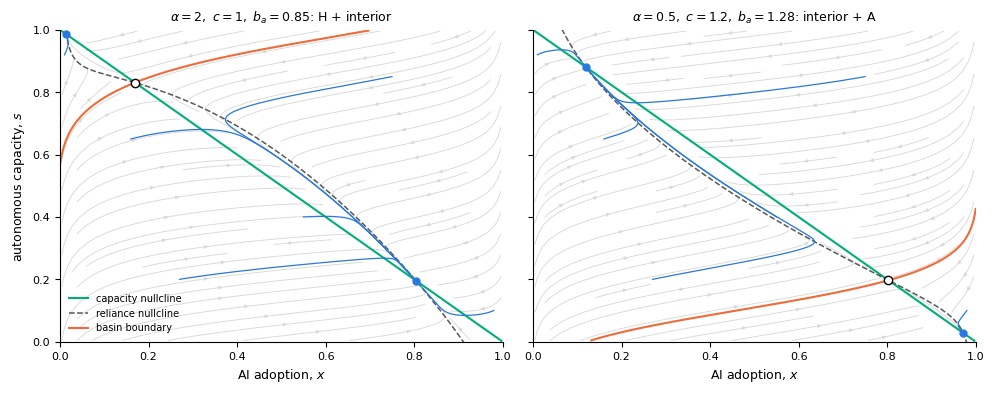

In [ ]:
# FIGURE 3 — phase portraits for the two additional bistable regimes
fig,axs=plt.subplots(1,2,figsize=(10,4),sharex=True,sharey=True)
cases=[(2,1,.85,'H + interior'),(.5,1.2,1.28,'interior + A')]
for ax,(alpha,c,a,name) in zip(axs,cases):
    xx=np.linspace(.004,.996,28); ss=np.linspace(.004,.996,28)
    X,S=np.meshgrid(xx,ss)
    U=X*(1-X)*(a-S-c*X**alpha)+M*(1-2*X)
    V=EPS*(1-X-S)
    ax.streamplot(xx,ss,U,V,color='#dad9d5',density=1.0,arrowsize=.5,linewidth=.65)
    x=np.linspace(.003,.997,2200)
    ax.plot(x,1-x,color='#00ae78',lw=1.5,label='capacity nullcline')
    ns=a-c*x**alpha+M*(1-2*x)/(x*(1-x))
    ax.plot(x,ns,'--',color='.35',lw=1.1,label='reliance nullcline')
    roots=stationary_roots(a,c,alpha)
    stable=[r for r in roots if feedback(r,c,alpha)-M*phi(r)<0]
    saddle=[r for r in roots if feedback(r,c,alpha)-M*phi(r)>0][0]
    ys=np.array([saddle,1-saddle]); e=1e-6
    # The negative-eigenvalue eigenvector gives the stable separatrix.
    J=np.array([[ (1-2*saddle)*(a-(1-saddle)-c*saddle**alpha)
                 -c*alpha*saddle**alpha*(1-saddle)-2*M,
                -saddle*(1-saddle)],[-EPS,-EPS]])
    eigenvalues,eigenvectors=np.linalg.eig(J)
    v=np.real(eigenvectors[:,np.argmin(np.real(eigenvalues))])
    v/=np.linalg.norm(v)
    for sg in [-1,1]:
        sol=solve_ivp(lambda t,y:-np.array(rhs(t,y,a,c,alpha)),(0,160),ys+sg*e*v,
                      max_step=.2,rtol=1e-8,atol=1e-10)
        ok=(sol.y[0]>=0)&(sol.y[0]<=1)&(sol.y[1]>=0)&(sol.y[1]<=1)
        ax.plot(sol.y[0,ok],sol.y[1,ok],color='#ef6b3a',lw=1.5,
                label='basin boundary' if sg==-1 else None)
    for initial in [(0.01,.92),(.16,.65),(.55,.4),(.98,.1),(.75,.85),(.27,.2)]:
        sol=solve_ivp(lambda t,y:rhs(t,y,a,c,alpha),(0,220),initial,max_step=.35)
        ax.plot(sol.y[0],sol.y[1],color='#2878dd',lw=.9)
    for r in stable: ax.plot(r,1-r,'o',mfc='#2878dd',mec='#2878dd',ms=5,zorder=8)
    ax.plot(saddle,1-saddle,'o',mfc='white',mec='k',ms=6,zorder=9)
    ax.set(xlim=(0,1),ylim=(0,1),xlabel=r'AI adoption, $x$')
    ax.set_title(fr'$\alpha={alpha:g},\ c={c:g},\ b_a={a:.2f}$: {name}',fontsize=9)
axs[0].set_ylabel(r'autonomous capacity, $s$')
axs[0].legend(frameon=False,fontsize=7,loc='lower left')
fig.tight_layout(); finish(fig,3)



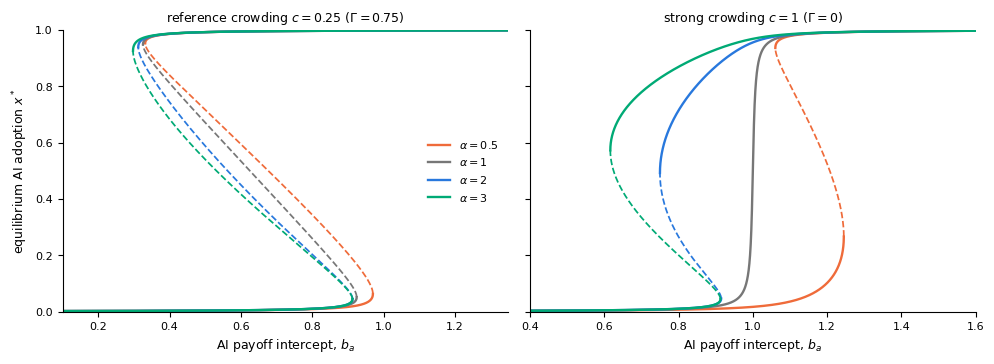

In [ ]:
# FIGURE 4 — equilibrium branches for weak and strong crowding
fig,axs=plt.subplots(1,2,figsize=(10,3.7),sharey=True)
x=np.linspace(.001,.999,9000)
for ax,c in zip(axs,[.25,1.0]):
    for alpha in [.5,1,2,3]:
        y=ae(x,c,alpha)
        stable=feedback(x,c,alpha)-M*phi(x)<0
        ax.plot(np.where(stable,y,np.nan),x,color=COL[alpha],lw=1.7,
                label=fr'$\alpha={alpha:g}$')
        ax.plot(np.where(~stable,y,np.nan),x,'--',color=COL[alpha],lw=1.25)
    ax.set_xlim((.1,1.35) if c==.25 else (.4,1.6))
    ax.set_ylim(0,1)
    ax.set_xlabel(r'AI payoff intercept, $b_a$')
    ax.set_title(fr"{'reference' if c==.25 else 'strong'} crowding $c={c:g}$ "
                 +fr'$(\Gamma={1-c:g})$',fontsize=9)
axs[0].set_ylabel(r'equilibrium AI adoption $x^*$')
axs[0].legend(frameon=False,loc='center right',fontsize=8)
fig.tight_layout(); finish(fig,4)



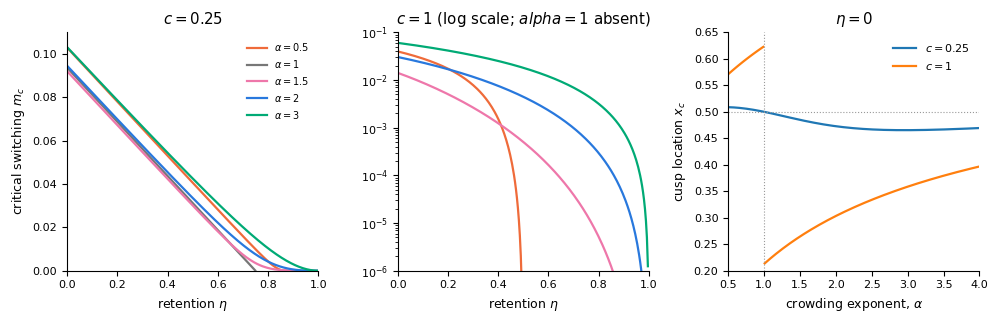

In [ ]:
# FIGURE 5 — critical switching rate and cusp location
def critical(c,alpha,eta):
    target=lambda z:-(B_H*(1-eta)-c*alpha*z**(alpha-1))/phi(z)
    opt=minimize_scalar(target,bounds=(1e-7,1-1e-7),method='bounded',
                        options={'xatol':1e-12})
    return max(0.,-opt.fun),opt.x

fig,axs=plt.subplots(1,3,figsize=(10,3.3))
etas=np.linspace(0,1,260)
for ax,c in zip(axs[:2],[.25,1.0]):
    for alpha in [.5,1,1.5,2,3]:
        rates=np.array([critical(c,alpha,eta)[0] for eta in etas])
        if c==1 and alpha==1: continue
        ax.plot(etas,np.where(rates>0,rates,np.nan),color=COL[alpha],lw=1.6,
                label=fr'$\alpha={alpha:g}$')
    ax.set(xlim=(0,1),xlabel=r'retention $\eta$',title=fr'$c={c:g}$')
axs[0].set(ylim=(0,.11),ylabel=r'critical switching $m_c$')
axs[0].legend(fontsize=7,frameon=False)
axs[1].set_yscale('log'); axs[1].set_ylim(1e-6,1e-1)
axs[1].set_title(r'$c=1$ (log scale; $alpha=1$ absent)')
gvals=np.linspace(.5,4,180)
for c in [.25,1]:
    xc=np.array([critical(c,g,0)[1] for g in gvals])
    if c==1:
        for keep in [gvals<1,gvals>1]:
            axs[2].plot(gvals[keep],xc[keep],lw=1.6,color='#ff7f0e',
                        label=fr'$c={c:g}$' if keep[0] else None)
    else:
        axs[2].plot(gvals,xc,lw=1.6,color='#1f77b4',label=fr'$c={c:g}$')
axs[2].axhline(.5,ls=':',lw=.8,color='0.6')
axs[2].axvline(1,ls=':',lw=.8,color='0.6')
axs[2].set(xlim=(.5,4),ylim=(.2,.65),xlabel=r'crowding exponent, $\alpha$',
           ylabel=r'cusp location $x_c$',title=r'$\eta=0$')
axs[2].legend(frameon=False,fontsize=8)
fig.tight_layout(); finish(fig,5)



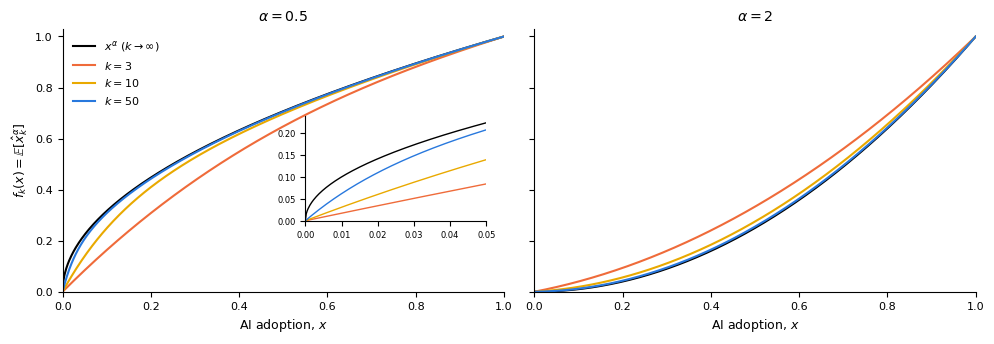

In [ ]:
# FIGURE 6 — sampled crowding (Bernstein smoothing)
def sampled_crowding(x,k,alpha):
    j=np.arange(k+1)
    return binom.pmf(j[None,:],k,np.asarray(x)[:,None]) @ (j/k)**alpha

fig,axs=plt.subplots(1,2,figsize=(10,3.5),sharey=True)
x=np.linspace(0,1,600)
sample_colors={3:'#ef6b3a',10:'#e9a900',50:'#2878dd'}
for ax,alpha in zip(axs,[.5,2]):
    ax.plot(x,x**alpha,color='k',lw=1.5,label=r'$x^\alpha$ ($k\to\infty$)')
    for k in [3,10,50]:
        ax.plot(x,sampled_crowding(x,k,alpha),color=sample_colors[k],lw=1.5,
                label=fr'$k={k}$')
    ax.set(xlim=(0,1),ylim=(0,1.03),xlabel=r'AI adoption, $x$',
           title=fr'$\alpha={alpha:g}$')
axs[0].set_ylabel(r'$f_k(x)=\mathbb{E}[\hat x_k^\alpha]$')
axs[0].legend(frameon=False,fontsize=8,loc='upper left')
inset=axs[0].inset_axes([.55,.27,.41,.40])
near=np.linspace(0,.05,200)
inset.plot(near,near**.5,color='k',lw=1)
for k in [3,10,50]:
    inset.plot(near,sampled_crowding(near,k,.5),color=sample_colors[k],lw=1)
inset.set(xlim=(0,.05),ylim=(0,.24))
inset.tick_params(labelsize=6)
fig.tight_layout(); finish(fig,6)


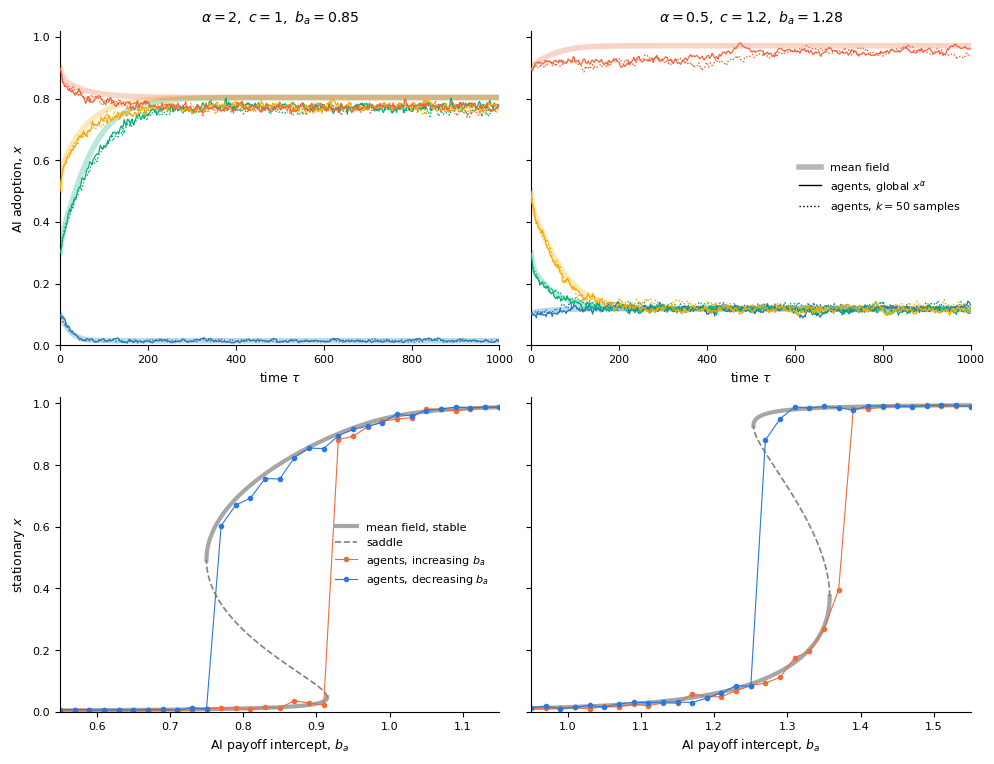

In [ ]:
# FIGURE 7 — agent-based validation and quasi-static hysteresis
# This is the computationally intensive cell. In Colab, Numba compiles the
# event loop on first use. Set FAST_PREVIEW=True for a short layout check.
try:
    from numba import njit
except ImportError:
    raise ImportError('Install Numba in Colab with %pip install numba, then rerun.')

FAST_PREVIEW = False
BETA = .5
W = BETA/2
MU = M*W/(1+M*W)
KAPPA = (1-MU)*W                       # tau = KAPPA * sweeps
EPS_SWEEP = KAPPA*EPS
N_TOP = 2000 if FAST_PREVIEW else 20000
N_SWEEP = 300 if FAST_PREVIEW else 2000
TAU_MAX = 80 if FAST_PREVIEW else 1000
RELAX = 80 if FAST_PREVIEW else 1500  # sweeps per payoff value
MEASURE = 20 if FAST_PREVIEW else 300 # sweeps per payoff value
N_VALUES = 13 if FAST_PREVIEW else 31
TOP_STEP = 4 if FAST_PREVIEW else 2   # rescaled-time observation interval

@njit
def seed_events(seed):
    np.random.seed(seed)

@njit
def event_run(z, skills, last, n_ai, first_event, n_events,
              benefit, crowd, exponent, sampled, sample_k,
              beta, mutation, eps_sweep):
    """Sequential focal/model revisions; skills updated exactly on access."""
    n = len(z)
    for ev in range(n_events):
        now = (first_event+ev+1)/n         # time in sweeps
        i = np.random.randint(n)
        old = z[i]
        if np.random.random() < mutation:
            target = 1.0 if old == 0 else 0.0  # eta=0 in Fig. 7
            skills[i] = target+(skills[i]-target)*np.exp(-eps_sweep*(now-last[i]))
            last[i] = now
            z[i] = 1-old
            n_ai += 1 if old == 0 else -1
            continue
        j = np.random.randint(n-1)
        if j >= i: j += 1
        if z[j] == old: continue
        # Advance the autonomous agent's skill to this encounter.
        h = i if old == 0 else j
        skills[h] = 1.0+(skills[h]-1.0)*np.exp(-eps_sweep*(now-last[h]))
        last[h] = now
        xhat = n_ai/n
        if sampled: xhat = np.random.binomial(sample_k, xhat)/sample_k
        advantage = benefit-crowd*xhat**exponent-skills[h]
        delta = advantage if z[j] == 1 else -advantage
        if np.random.random() < 1/(1+np.exp(-beta*delta)):
            # Advance the focal AI user's skill before copying H.
            if old == 1:
                skills[i] *= np.exp(-eps_sweep*(now-last[i]))
                last[i] = now
            z[i] = z[j]
            n_ai += 1 if z[j] == 1 else -1
    return n_ai

def make_population(n,x0,s0):
    z=np.zeros(n,np.uint8)
    z[:round(n*x0)]=1
    np.random.shuffle(z)
    return z,np.full(n,s0,np.float64),np.zeros(n,np.float64),int(z.sum())

def abm_trajectory(n,x0,s0,a,c,alpha,sampled,seed):
    np.random.seed(seed)
    seed_events(seed)
    z,skills,last,count=make_population(n,x0,s0)
    steps=np.arange(0,TAU_MAX+1,TOP_STEP,dtype=float)
    out=np.empty(len(steps)); out[0]=count/n
    event_count=0
    for q in range(1,len(steps)):
        total=round(steps[q]*n/KAPPA)
        count=event_run(z,skills,last,count,event_count,total-event_count,
                        a,c,alpha,sampled,50,BETA,MU,EPS_SWEEP)
        event_count=total
        out[q]=count/n
    return steps,out

def abm_sweep(n,grid,c,alpha,start_x,seed):
    np.random.seed(seed)
    seed_events(seed)
    z,skills,last,count=make_population(n,start_x,1-start_x)
    event_count=0
    means=[]
    for a in grid:
        burn=n*RELAX
        count=event_run(z,skills,last,count,event_count,burn,
                        a,c,alpha,False,50,BETA,MU,EPS_SWEEP)
        event_count+=burn
        vals=[]
        for _ in range(10):
            chunk=n*MEASURE//10
            count=event_run(z,skills,last,count,event_count,chunk,
                            a,c,alpha,False,50,BETA,MU,EPS_SWEEP)
            event_count+=chunk
            vals.append(count/n)
        means.append(np.mean(vals))
    return np.array(means),(z,skills,last,count,event_count)

fig,axes=plt.subplots(2,2,figsize=(10,7.7),sharey='row')
fig7_cases=[(2,1,.85,(.55,1.15)),(.5,1.2,1.28,(.95,1.55))]
starts=[(.10,.90),(.30,.70),(.50,.50),(.90,.10)]
initial_colors=['#1f77b4','#00ae78','#f5aa00','#f0643c']
for j,(alpha,c,a,lim) in enumerate(fig7_cases):
    top=axes[0,j]; bottom=axes[1,j]
    for q,((x0,s0),color) in enumerate(zip(starts,initial_colors)):
        tt=np.linspace(0,TAU_MAX,1001)
        sol=solve_ivp(lambda t,y:rhs(t,y,a,c,alpha),[0,TAU_MAX],(x0,s0),
                      t_eval=tt,rtol=1e-8,atol=1e-10)
        top.plot(tt,sol.y[0],color=color,lw=4,alpha=.28,zorder=1)
        tg,xg=abm_trajectory(N_TOP,x0,s0,a,c,alpha,False,41000+20*j+q)
        sampled_seed=51024 if (j==1 and q==3) else 51000+20*j+q
        _,xs=abm_trajectory(N_TOP,x0,s0,a,c,alpha,True,sampled_seed)
        top.plot(tg,xg,color=color,lw=.9,zorder=3)
        top.plot(tg,xs,color=color,lw=1,ls=':',zorder=2)
    top.set(xlim=(0,TAU_MAX),ylim=(0,1.02),xlabel=r'time $\tau$',
            title=fr'$\alpha={alpha:g},\ c={c:g},\ b_a={a:g}$')
    grid=np.linspace(lim[0],lim[1],N_VALUES)
    # Smooth mean-field branches, with their stability classification.
    xx=np.linspace(.001,.999,6000)
    curve=ae(xx,c,alpha)
    is_stable=feedback(xx,c,alpha)-M*phi(xx)<0
    bottom.plot(np.where(is_stable,curve,np.nan),xx,color='0.65',lw=3,
                label='mean field, stable')
    bottom.plot(np.where(~is_stable,curve,np.nan),xx,'--',color='0.5',lw=1.2,
                label='saddle')
    up,ending=abm_sweep(N_SWEEP,grid,c,alpha,.01,61000+j)
    # Continue downward from the actual last state of the upward sweep.
    z,skills,last,count,event_count=ending
    down=[]
    for value in grid[::-1]:
        burn=N_SWEEP*RELAX
        count=event_run(z,skills,last,count,event_count,burn,value,c,alpha,
                        False,50,BETA,MU,EPS_SWEEP)
        event_count+=burn
        vals=[]
        for _ in range(10):
            chunk=N_SWEEP*MEASURE//10
            count=event_run(z,skills,last,count,event_count,chunk,value,c,alpha,
                            False,50,BETA,MU,EPS_SWEEP)
            event_count+=chunk
            vals.append(count/N_SWEEP)
        down.append(np.mean(vals))
    bottom.plot(grid,up,'o-',ms=3,lw=.8,color='#ef6b3a',label=r'agents, increasing $b_a$')
    bottom.plot(grid[::-1],down,'o-',ms=3,lw=.8,color='#2878dd',
                label=r'agents, decreasing $b_a$')
    bottom.set(xlim=lim,ylim=(0,1.02),xlabel=r'AI payoff intercept, $b_a$')
axes[0,0].set_ylabel(r'AI adoption, $x$')
axes[1,0].set_ylabel(r'stationary $x$')
axes[0,1].legend(handles=[Line2D([0],[0],color='0.6',lw=4,alpha=.7,label='mean field'),
                          Line2D([0],[0],color='k',lw=1,label=r'agents, global $x^\alpha$'),
                          Line2D([0],[0],color='k',lw=1,ls=':',label=r'agents, $k=50$ samples')],
                 frameon=False,fontsize=8,loc='center right')
axes[1,0].legend(frameon=False,fontsize=8,loc='center right')
fig.tight_layout(); finish(fig,7)
